# EDA na Prática: College English Learning Dataset

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias). Neste notebook eu sigo o mesmo roteiro da aula prática (feita com o Heart Disease), só que aplicado no dataset que escolhi. Quando algum passo da aula não precisou ser feito aqui, deixo escrito o motivo.

**Sobre o dataset:** o *College English Learning Dataset* (Kaggle, usuário ziya07) tem 500 alunos universitários que usaram uma plataforma de aprendizado de inglês. Para cada aluno temos:

- **perfil:** idade, gênero, proficiência prévia em inglês, estilo de aprendizagem e nível de motivação;
- **uso da plataforma:** tempo total gasto e frequência de uso;
- **notas antes e depois** em três habilidades: vocabulário, compreensão de leitura e fala;
- **ganho (Improvement)** em cada habilidade, que o próprio dataset marca como variável-alvo.

Assim como na aula, a análise é iterativa: olho a estatística descritiva **antes** de decidir o tratamento e **depois**, pra confirmar o efeito.

## Setup de Bibliotecas e Dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra classe de referência (Baixo ganho)
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse (Alto ganho)
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [ ]:
import os

# No Colab o arquivo csv foi enviado para /content/sample_data.

path = "/content/sample_data/english_learning_dataset_with_targets.csv"
if not os.path.exists(path):
    path = "english_learning_dataset_with_targets.csv"

df = pd.read_csv(path)
df.head()

,Student_ID,Age,Gender,Prior_English_Proficiency,Learning_Style,Motivation_Level,Time_Spent_Platform,Platform_Usage_Frequency,Vocabulary_Pre,Reading_Comprehension_Pre,Speaking_Pre,Vocabulary_Post,Reading_Comprehension_Post,Speaking_Post,Vocabulary_Improvement,Reading_Improvement,Speaking_Improvement
0,7365,19,Female,58,Kinesthetic,1,43,1,86,89,92,53,94,58,10,18,10
1,8555,23,Male,76,Auditory,4,125,4,67,51,57,63,69,51,18,19,15
2,1167,20,Male,54,Auditory,2,103,6,58,83,73,84,99,60,24,20,16
3,5341,19,Female,68,Auditory,4,153,4,78,53,97,71,60,53,-2,14,6
4,1773,21,Male,51,Auditory,3,133,3,55,53,80,94,84,72,4,7,25


## 1. Princípio Estrutural


**Antes de rodar:** A base tem um ID, 5 variáveis de perfil, 2 de uso da plataforma e 9 colunas de notas/ganho (17 colunas). Com 500 linhas o tamanho é razoável: dá pra tirar conclusões, mas não é tão grande a ponto de qualquer diferença mínima virar "significativa" nos testes.

### Dimensão e Tipos de Dados

In [ ]:
df.shape

(500, 17)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 17 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Student_ID                  500 non-null    int64 
 1   Age                         500 non-null    int64 
 2   Gender                      500 non-null    object
 3   Prior_English_Proficiency   500 non-null    int64 
 4   Learning_Style              500 non-null    object
 5   Motivation_Level            500 non-null    int64 
 6   Time_Spent_Platform         500 non-null    int64 
 7   Platform_Usage_Frequency    500 non-null    int64 
 8   Vocabulary_Pre              500 non-null    int64 
 9   Reading_Comprehension_Pre   500 non-null    int64 
 10  Speaking_Pre                500 non-null    int64 
 11  Vocabulary_Post             500 non-null    int64 
 12  Reading_Comprehension_Post  500 non-null    int64 
 13  Speaking_Post               500 non-null    int64 

In [ ]:
df.describe()

,Student_ID,Age,Prior_English_Proficiency,Motivation_Level,Time_Spent_Platform,Platform_Usage_Frequency,Vocabulary_Pre,Reading_Comprehension_Pre,Speaking_Pre,Vocabulary_Post,Reading_Comprehension_Post,Speaking_Post,Vocabulary_Improvement,Reading_Improvement,Speaking_Improvement
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,5386.250000,21.076000,74.280000,2.516000,108.148000,3.308000,73.294000,74.628000,74.626000,74.702000,74.680000,74.450000,9.456000,9.836000,9.734000
std,2647.022682,1.918746,14.539339,1.119039,41.901953,1.626785,14.040721,14.814877,14.272264,14.005052,14.704899,15.009132,11.477436,11.354248,11.709204
min,1024.000000,18.000000,50.000000,1.000000,30.000000,1.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,-10.000000,-10.000000,-10.000000
25%,3050.750000,19.000000,62.000000,2.000000,73.000000,2.000000,62.000000,62.000000,63.000000,64.000000,62.000000,61.000000,-1.000000,1.000000,-1.000000
50%,5324.500000,21.000000,74.000000,3.000000,111.500000,3.000000,73.000000,76.000000,74.000000,75.000000,75.000000,75.000000,10.000000,10.000000,10.000000
75%,7696.500000,23.000000,88.000000,4.000000,143.000000,5.000000,85.000000,87.000000,87.000000,86.000000,88.000000,87.000000,19.000000,19.000000,20.000000
max,9977.000000,24.000000,99.000000,4.000000,179.000000,6.000000,99.000000,99.000000,99.000000,99.000000,99.000000,99.000000,29.000000,29.000000,29.000000


**O que dá pra tirar do `info()` e do `describe()`:**

- Todas as colunas são numéricas inteiras, menos `Gender` e `Learning_Style` (texto).
- `Motivation_Level` (1 a 4) e `Platform_Usage_Frequency` (1 a 6) são números, mas representam **níveis**, não medidas. Vou tratar as duas como qualitativas ordinais.
- `Student_ID` é só um identificador, então não entra em nenhuma estatística.
- As notas (pré e pós) e a proficiência prévia vão de 50 a 99, a idade de 18 a 24 e o tempo de plataforma de 30 a 179. As colunas de ganho vão de -10 a 29.

**Tipos de dados:** nenhuma conversão foi necessária. O pandas já leu cada coluna com um tipo compatível com o conteúdo (não tem número salvo como texto, por exemplo).

### Duplicadas

In [ ]:
print("Linhas completamente duplicadas:", df.duplicated().sum())
print("Student_ID repetidos:", df["Student_ID"].duplicated().sum())

Linhas completamente duplicadas: 0
Student_ID repetidos: 7


Nenhuma linha é totalmente duplicada, mas **7 valores de `Student_ID` aparecem duas vezes**. Checar só linhas idênticas não basta, porque o mesmo aluno poderia ter sido registrado duas vezes com algum valor diferente. Então olhei essas linhas:

In [ ]:
df[df["Student_ID"].duplicated(keep=False)].sort_values("Student_ID")

,Student_ID,Age,Gender,Prior_English_Proficiency,Learning_Style,Motivation_Level,Time_Spent_Platform,Platform_Usage_Frequency,Vocabulary_Pre,Reading_Comprehension_Pre,Speaking_Pre,Vocabulary_Post,Reading_Comprehension_Post,Speaking_Post,Vocabulary_Improvement,Reading_Improvement,Speaking_Improvement
92,2590,21,Female,68,Kinesthetic,1,151,1,98,61,54,70,62,98,8,-5,3
148,2590,18,Female,54,Kinesthetic,1,87,4,51,77,89,88,56,69,19,28,-9
483,3425,24,Male,98,Visual,2,163,2,73,91,58,77,67,87,-2,20,21
341,3425,18,Male,63,Auditory,2,117,3,50,51,50,62,85,77,-6,2,12
150,3958,18,Male,92,Kinesthetic,1,107,2,83,81,77,65,67,70,1,5,10
59,3958,22,Female,59,Auditory,4,174,1,79,64,97,84,94,67,-1,28,5
143,4032,18,Female,70,Visual,1,167,3,85,79,92,74,85,56,2,15,4
255,4032,23,Male,90,Auditory,1,116,5,71,94,79,67,70,66,24,15,10
434,8146,23,Female,50,Kinesthetic,3,67,4,91,91,52,94,92,53,-6,5,12
252,8146,24,Male,92,Kinesthetic,2,116,2,72,74,74,81,61,74,26,-3,-3


Os pares com o mesmo ID têm idades diferentes (ex: ID 2590 com 21 e 18 anos), às vezes gênero diferente (ID 3958 e 4032) e notas totalmente diferentes. Não faz sentido ser o mesmo aluno registrado duas vezes, parece mais que o ID foi sorteado e repetiu por coincidência (são números de 4 dígitos para 500 alunos).

**Decisão:** não removi nenhuma linha. Cada linha é um aluno diferente, e como o `Student_ID` não é usado em nenhuma análise, a repetição não atrapalha nada.

### Criando o atributo alvo

**Renomear:** na aula, a coluna `num` foi renomeada/transformada em `doenca_cardiaca` porque o nome não dizia nada. Aqui **não renomeei nenhuma coluna**: os nomes já são descritivos (`Time_Spent_Platform`, `Vocabulary_Pre` etc.), e trocar tudo aumentaria a chance de erro no código sem ganho de interpretação.

**Criar o alvo:** o dataset traz o ganho separado em três colunas (`Vocabulary_Improvement`, `Reading_Improvement` e `Speaking_Improvement`). Pra ter uma única variável de desfecho, calculei o **ganho médio** das três habilidades e transformei em uma variável binária usando a **mediana** como corte:

- **Alto ganho** (roxo): ganho médio igual ou acima da mediana;
- **Baixo ganho** (rosa): ganho médio abaixo da mediana.

Não existe um ponto de corte "oficial" pra dizer que um aluno teve bom ganho. Usar ganho > 0 parece natural, mas deixaria o grupo "não melhorou" muito pequeno (o código abaixo mostra quantos seriam). A mediana gera dois grupos de tamanho parecido, o que deixa as comparações mais justas. Em troca, o alvo fica balanceado *por construção*, e isso precisa ser lembrado quando olharmos o desbalanceamento mais à frente.

Não apaguei as colunas originais de ganho porque vou precisar delas na Seção 4 pra checar se os dados são consistentes.

In [ ]:
COLS_PRE = ["Vocabulary_Pre", "Reading_Comprehension_Pre", "Speaking_Pre"]
COLS_POS = ["Vocabulary_Post", "Reading_Comprehension_Post", "Speaking_Post"]
COLS_GANHO = ["Vocabulary_Improvement", "Reading_Improvement", "Speaking_Improvement"]

df["ganho_medio"] = df[COLS_GANHO].mean(axis=1)

mediana_ganho = df["ganho_medio"].median()
df["desempenho"] = np.where(df["ganho_medio"] >= mediana_ganho, "Alto ganho", "Baixo ganho")

print(f"Mediana do ganho médio: {mediana_ganho:.2f}")
print(f"Alunos com ganho médio <= 0 (seriam o grupo 'não melhorou'): {(df['ganho_medio'] <= 0).sum()}")
df["desempenho"].value_counts()


Mediana do ganho médio: 10.00
Alunos com ganho médio <= 0 (seriam o grupo 'não melhorou'): 39


,count
desempenho,
Alto ganho,254
Baixo ganho,246


Os grupos ficaram com 254 e 246 alunos, e não exatamente 250/250. Isso acontece porque vários alunos têm ganho médio exatamente igual à mediana (10) e, pela regra `>=`, todos eles caem em "Alto ganho".

## 2. Dados Faltantes

In [ ]:
total_nulos = df.isna().sum().sum()
print(f"Total de valores nulos no dataset: {total_nulos}")

if total_nulos == 0:
    print("O dataset atual não possui valores ausentes.")
else:
    cols_com_ausentes = df.columns[df.isna().any()].tolist()
    print("Colunas com ausentes:", cols_com_ausentes)
    print(df[cols_com_ausentes].isna().sum())

Total de valores nulos no dataset: 0
O dataset atual não possui valores ausentes.


**Discussão:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*: Não. Nenhuma das 17 colunas tem valor nulo.

#### Identificando o mecanismo de dados ausentes

Como não há nenhum `NaN`, a discussão de mecanismo (MCAR/MAR/MNAR) e o heatmap de "as ausências ocorrem juntas?" da aula **não se aplicam** aqui: não existe ausência pra classificar nem pra cruzar.

Mas "zero NaN" não garante que não falta nada. Às vezes a ausência vem **disfarçada**: um 0 no lugar de uma nota que não foi registrada, uma idade impossível ou uma categoria tipo "Unknown". Então, em vez de só pular a seção, fiz uma checagem de valores fora do que faz sentido.

In [ ]:
print("Categorias encontradas nas variáveis de texto:")
for col in ["Gender", "Learning_Style"]:
    print(f"  {col}: {sorted(df[col].unique())}")

COLS_NOTAS = COLS_PRE + COLS_POS
checagens = {
    "Idade fora de 16 a 60 anos": ~df["Age"].between(16, 60),
    "Alguma nota fora de 0 a 100": ~df[COLS_NOTAS].apply(lambda s: s.between(0, 100)).all(axis=1),
    "Alguma nota igual a 0": (df[COLS_NOTAS] == 0).any(axis=1),
    "Tempo na plataforma <= 0": df["Time_Spent_Platform"] <= 0,
}

pd.Series({nome: int(mascara.sum()) for nome, mascara in checagens.items()}, name="linhas_suspeitas")

Categorias encontradas nas variáveis de texto:
  Gender: ['Female', 'Male']
  Learning_Style: ['Auditory', 'Kinesthetic', 'Visual']


,linhas_suspeitas
Idade fora de 16 a 60 anos,0
Alguma nota fora de 0 a 100,0
Alguma nota igual a 0,0
Tempo na plataforma <= 0,0


Nenhuma checagem encontrou problema: `Gender` só tem Female/Male, `Learning_Style` só tem os três estilos esperados, as idades vão de 18 a 24, as notas ficam entre 50 e 99 e todos os tempos de uso são positivos. Então a base também não tem nulos disfarçados.

## 3. Princípio Distribucional

Ainda com os dados originais, vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção.

Separei as variáveis em três grupos:

- `VARS_QUANT`: todas as numéricas contínuas (usadas nas tabelas, outliers e correlação);
- `VARS_PREDITORAS`: só o que existe **antes** do curso (idade, proficiência prévia, tempo de plataforma e notas pré). São essas que comparo entre "Alto ganho" e "Baixo ganho". Deixo de fora as notas pós e os ganhos, porque o alvo foi construído a partir dos ganhos, e comparar o ganho entre grupos definidos pelo próprio ganho seria circular;
- `VARS_QUALI`: gênero, estilo de aprendizagem e as duas escalas ordinais (motivação de 1 a 4 e frequência de uso de 1 a 6). As escalas são números, mas representam níveis, não medidas, então tratamos como categorias.

O `Student_ID` fica de fora de tudo, porque é só um identificador.

In [ ]:
VARS_PREDITORAS = ["Age", "Prior_English_Proficiency", "Time_Spent_Platform"] + COLS_PRE
VARS_QUANT = VARS_PREDITORAS + COLS_POS + COLS_GANHO
VARS_QUALI = ["Gender", "Learning_Style", "Motivation_Level", "Platform_Usage_Frequency"]

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
Age,21.08,21.00,1.92,18.00,24.00,-0.08,-1.17
Prior_English_Proficiency,74.28,74.00,14.54,50.00,99.00,0.01,-1.22
Time_Spent_Platform,108.15,111.50,41.90,30.00,179.00,-0.14,-1.10
Vocabulary_Pre,73.29,73.00,14.04,50.00,99.00,0.11,-1.10
Reading_Comprehension_Pre,74.63,76.00,14.81,50.00,99.00,-0.04,-1.25
Speaking_Pre,74.63,74.00,14.27,50.00,99.00,0.04,-1.14
Vocabulary_Post,74.70,75.00,14.01,50.00,99.00,0.00,-1.08
Reading_Comprehension_Post,74.68,75.00,14.70,50.00,99.00,-0.00,-1.21
Speaking_Post,74.45,75.00,15.01,50.00,99.00,-0.02,-1.28
Vocabulary_Improvement,9.46,10.00,11.48,-10.00,29.00,0.03,-1.17


**Pra discutir:** olhando a tabela, quais variáveis parecem assimétricas (`skewness` acima de 1 em módulo) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

*Resposta*: Nenhuma, todas têm assimetria perto de 0 (menos de 0,15 em módulo), e a curtose de todas fica **negativa, perto de -1,2**. Curtose negativa quer dizer o contrário de cauda pesada: a distribuição é "achatada" e não tem valores extremos.

Esse padrão chamou atenção. Numa distribuição **uniforme** (todo valor com a mesma chance), a curtose é -1,2 e o desvio padrão é mais ou menos a amplitude dividida por $\sqrt{12}$. Pras notas de 50 a 99 isso dá $49/\sqrt{12} \approx 14{,}1$, e o desvio padrão real ficou perto de 14. Isso indica fortemente que os dados foram **gerados por computador** (sintéticos), e não coletados de alunos reais. Vou levar isso em conta no resto da análise.

### Distribuições de dados

Onde fizer sentido, comparo "Baixo ganho" (rosa) vs. "Alto ganho" (roxo). Essa convenção de cor segue até a análise bivariada.

No gráfico por classe só uso as `VARS_PREDITORAS`. Colocar os ganhos ali seria circular, já que as classes foram criadas a partir deles.

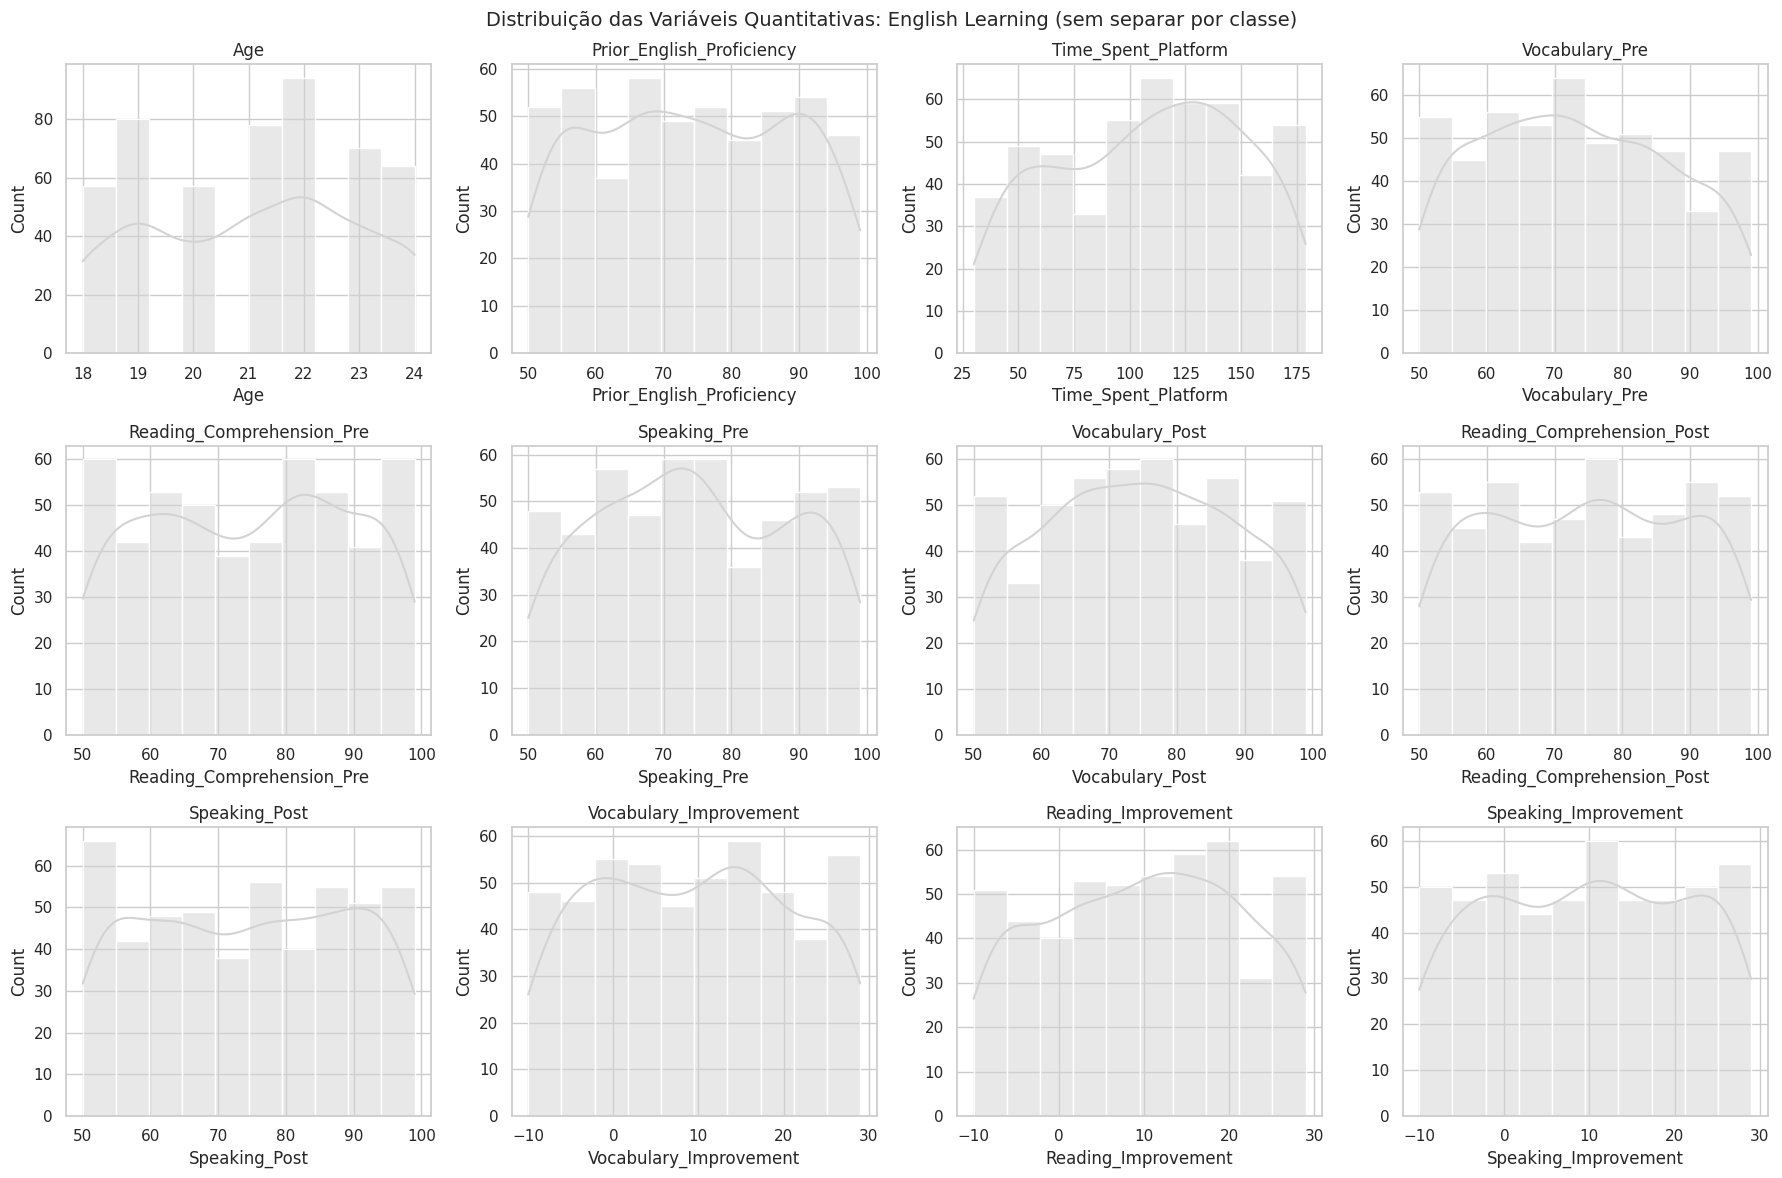

In [ ]:
n_cols = 4
n_linhas = int(np.ceil(len(VARS_QUANT) / n_cols))
fig, axes = plt.subplots(n_linhas, n_cols, figsize=(18, 4 * n_linhas))
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas: English Learning (sem separar por classe)", fontsize=14)
plt.tight_layout()
plt.show()

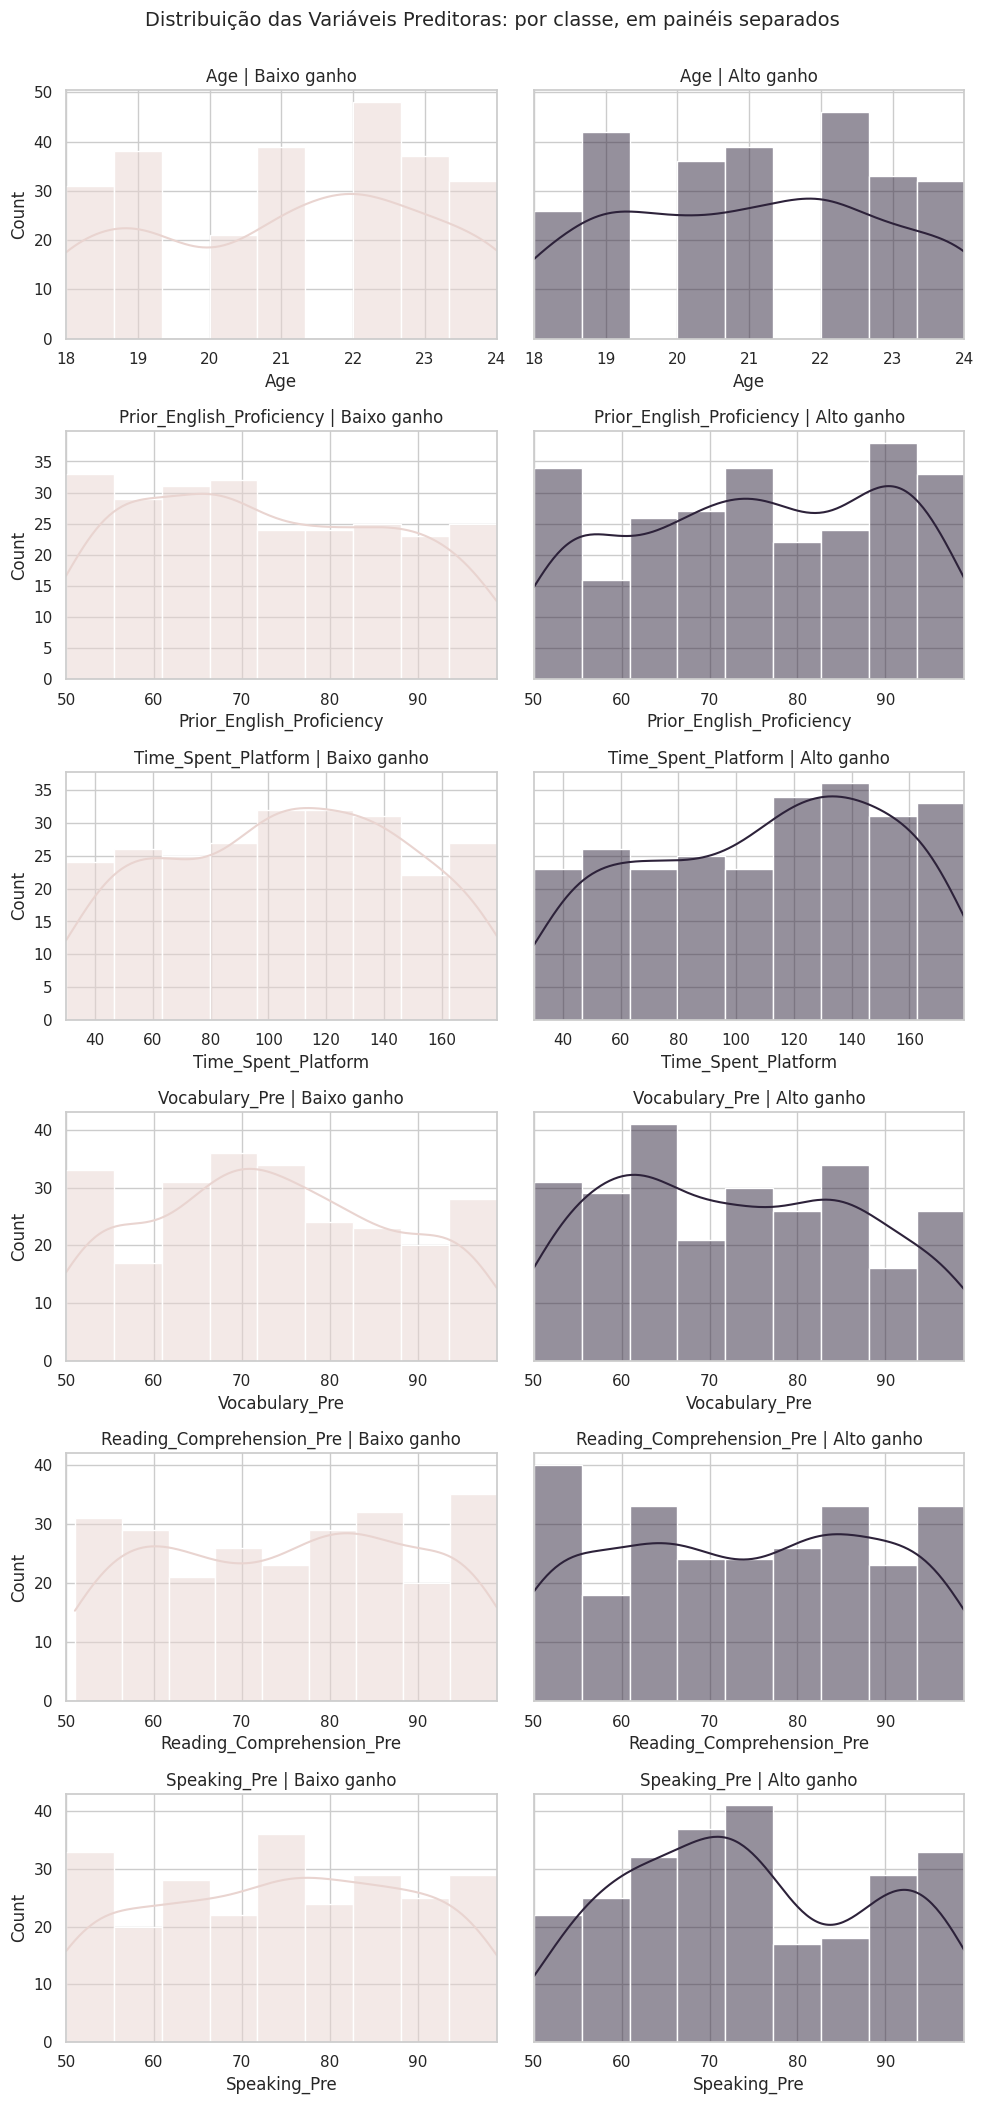

In [ ]:
fig, axes = plt.subplots(len(VARS_PREDITORAS), 2, figsize=(10, 3.5 * len(VARS_PREDITORAS)), sharey="row")

for i, col in enumerate(VARS_PREDITORAS):
    lim = (df[col].min(), df[col].max())
    for j, (classe, cor) in enumerate([("Baixo ganho", COR_CONTEXTO), ("Alto ganho", COR_DESTAQUE)]):
        subset = df[df["desempenho"] == classe]
        sns.histplot(data=subset, x=col, kde=True, color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} | {classe}")

fig.suptitle("Distribuição das Variáveis Preditoras: por classe, em painéis separados", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

**Para discutir:** com as classes em painéis separados (mesma escala no eixo X), alguma variável tem formato bem diferente entre "Baixo ganho" e "Alto ganho"?

*Resposta*: Não, em todas as variáveis de entrada (idade, proficiência prévia, tempo de plataforma e notas pré) os histogramas dos dois grupos têm praticamente o mesmo formato "achatado". Visualmente, nenhuma variável separa quem teve alto ganho de quem teve baixo ganho.

#### Testes de Aderência

*Será que o tempo gasto na plataforma segue uma distribuição normal?*

Escolhi `Time_Spent_Platform`, porque é a variável que mede o "esforço" do aluno e é a que mais faria sentido ter relação com o ganho. Uso o **Shapiro-Wilk** junto com o **QQ-Plot**.

Shapiro-Wilk | Time_Spent_Platform: estatística=0.9601, p-valor=2.169e-10
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


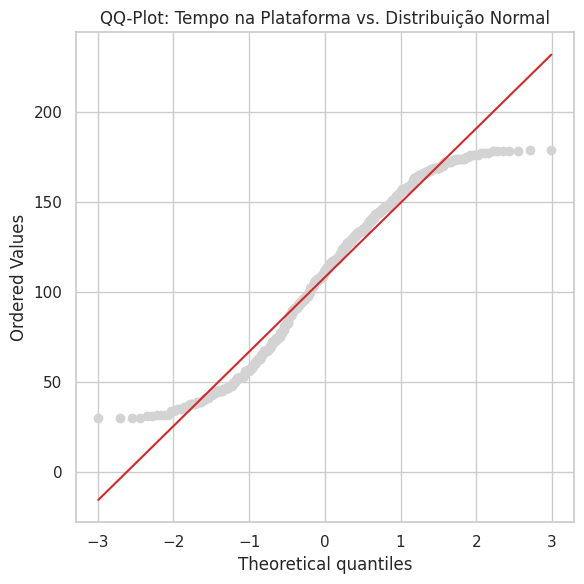

In [ ]:
stat_sw, p_valor_sw = stats.shapiro(df["Time_Spent_Platform"].dropna())
print(f"Shapiro-Wilk | Time_Spent_Platform: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["Time_Spent_Platform"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Tempo na Plataforma vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos seguissem a reta vermelha, a variável seria normal. Aqui os pontos formam um "S" deitado: nas pontas eles se afastam da reta. Isso acontece porque a uniforme tem mínimo e máximo "duros" (30 e 179) e não tem cauda nenhuma. O Shapiro-Wilk deu p-valor bem menor que 0,05, então **temos evidência contra a normalidade**.

**Cuidado com duas armadilhas (visto na aula):**

- **Tamanho da amostra:** amostra pequena tende a *não* rejeitar a normalidade, e amostra gigante rejeita por qualquer desvio pequeno. Com n = 500 e três evidências concordando (curtose negativa, QQ-Plot em "S" e Shapiro-Wilk), o resultado é confiável.
- **Como falar o resultado:** como o teste rejeitou H0, o certo é dizer "há evidência contra a normalidade". A frase "não dá pra garantir normalidade" seria usada no caso contrário, quando o teste não rejeita.

Por isso, nas comparações entre grupos mais à frente, o resultado principal vai ser o dos testes não-paramétricos.

In [ ]:
resultados_shapiro = []
for col in VARS_QUANT + ["ganho_medio"]:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": f"{p:.2e}", "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
Age,0.9255,4.87e-15,True
Prior_English_Proficiency,0.9510,7.99e-12,True
Time_Spent_Platform,0.9601,2.17e-10,True
Vocabulary_Pre,0.9594,1.66e-10,True
Reading_Comprehension_Pre,0.9465,1.87e-12,True
Speaking_Pre,0.9566,5.87e-11,True
Vocabulary_Post,0.9624,5.35e-10,True
Reading_Comprehension_Post,0.9505,6.97e-12,True
Speaking_Post,0.9426,5.53e-13,True


Todas as 12 variáveis quantitativas originais rejeitaram a normalidade, não só o tempo de plataforma. Isso é coerente com a tabela de assimetria/curtose: todas têm o mesmo formato achatado.

A exceção é o `ganho_medio` (p ≈ 0,32, **não rejeita**). Faz sentido: ele é a média de três colunas uniformes e independentes, e a média de várias variáveis independentes tende a formar um sino (Teorema Central do Limite). Lembrando que não rejeitar não prova normalidade, só indica que tratá-lo como aproximadamente normal é razoável.

**ECDF: outra forma de ver a distribuição**

A ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É útil pra comparar dois grupos, porque onde as curvas se afastam é onde os grupos mais diferem.

Uso de novo `Time_Spent_Platform`, separando por classe.

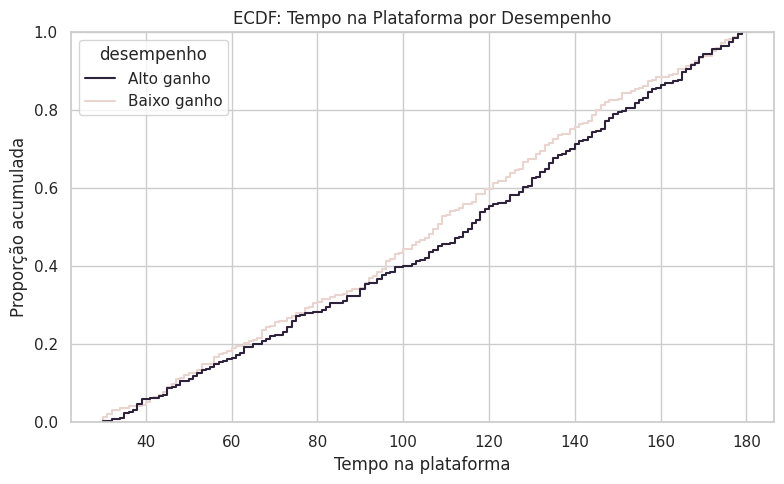

In [ ]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="Time_Spent_Platform", hue="desempenho",
             palette={"Baixo ganho": COR_CONTEXTO, "Alto ganho": COR_DESTAQUE})
plt.title("ECDF: Tempo na Plataforma por Desempenho")
plt.xlabel("Tempo na plataforma")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração dos alunos desse grupo usou a plataforma até esse tempo". Se a curva roxa ficasse **abaixo** da rosa, os alunos de alto ganho teriam usado mais a plataforma.

*Resposta*: as duas curvas são quase retas diagonais (o formato típico da uniforme) e ficam praticamente em cima uma da outra. Ou seja, quem teve alto ganho não usou a plataforma por mais tempo do que quem teve baixo ganho.

### Métricas de Tendência Central

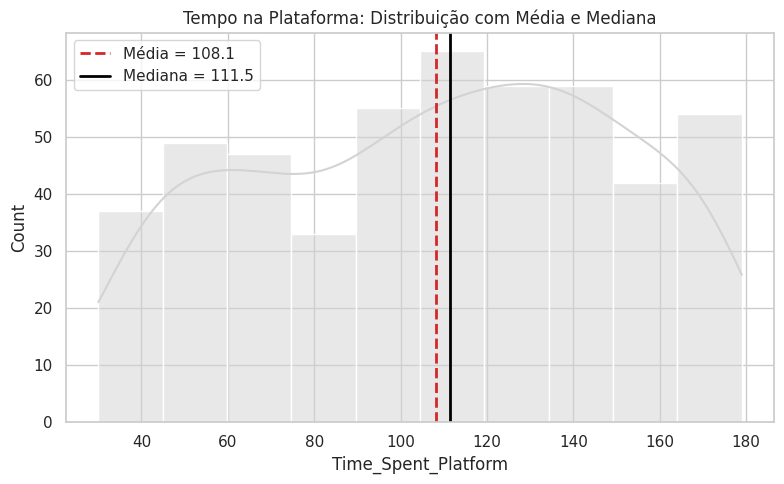

In [ ]:
media_tempo = df["Time_Spent_Platform"].mean()
mediana_tempo = df["Time_Spent_Platform"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Time_Spent_Platform", kde=True, color=COR_NEUTRA)
plt.axvline(media_tempo, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_tempo:.1f}")
plt.axvline(mediana_tempo, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_tempo:.1f}")
plt.title("Tempo na Plataforma: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

A média (≈108) e a mediana (≈112) ficaram próximas. Não existe cauda longa, então as duas medidas contam praticamente a mesma história e qualquer uma serviria como resumo.

### Dispersão

,var,std,IQR
Age,3.68,1.92,4.0
Prior_English_Proficiency,211.39,14.54,26.0
Time_Spent_Platform,1755.77,41.90,70.0
Vocabulary_Pre,197.14,14.04,23.0
Reading_Comprehension_Pre,219.48,14.81,25.0
Speaking_Pre,203.70,14.27,24.0
Vocabulary_Post,196.14,14.01,22.0
Reading_Comprehension_Post,216.23,14.70,26.0
Speaking_Post,225.27,15.01,26.0
Vocabulary_Improvement,131.73,11.48,20.0


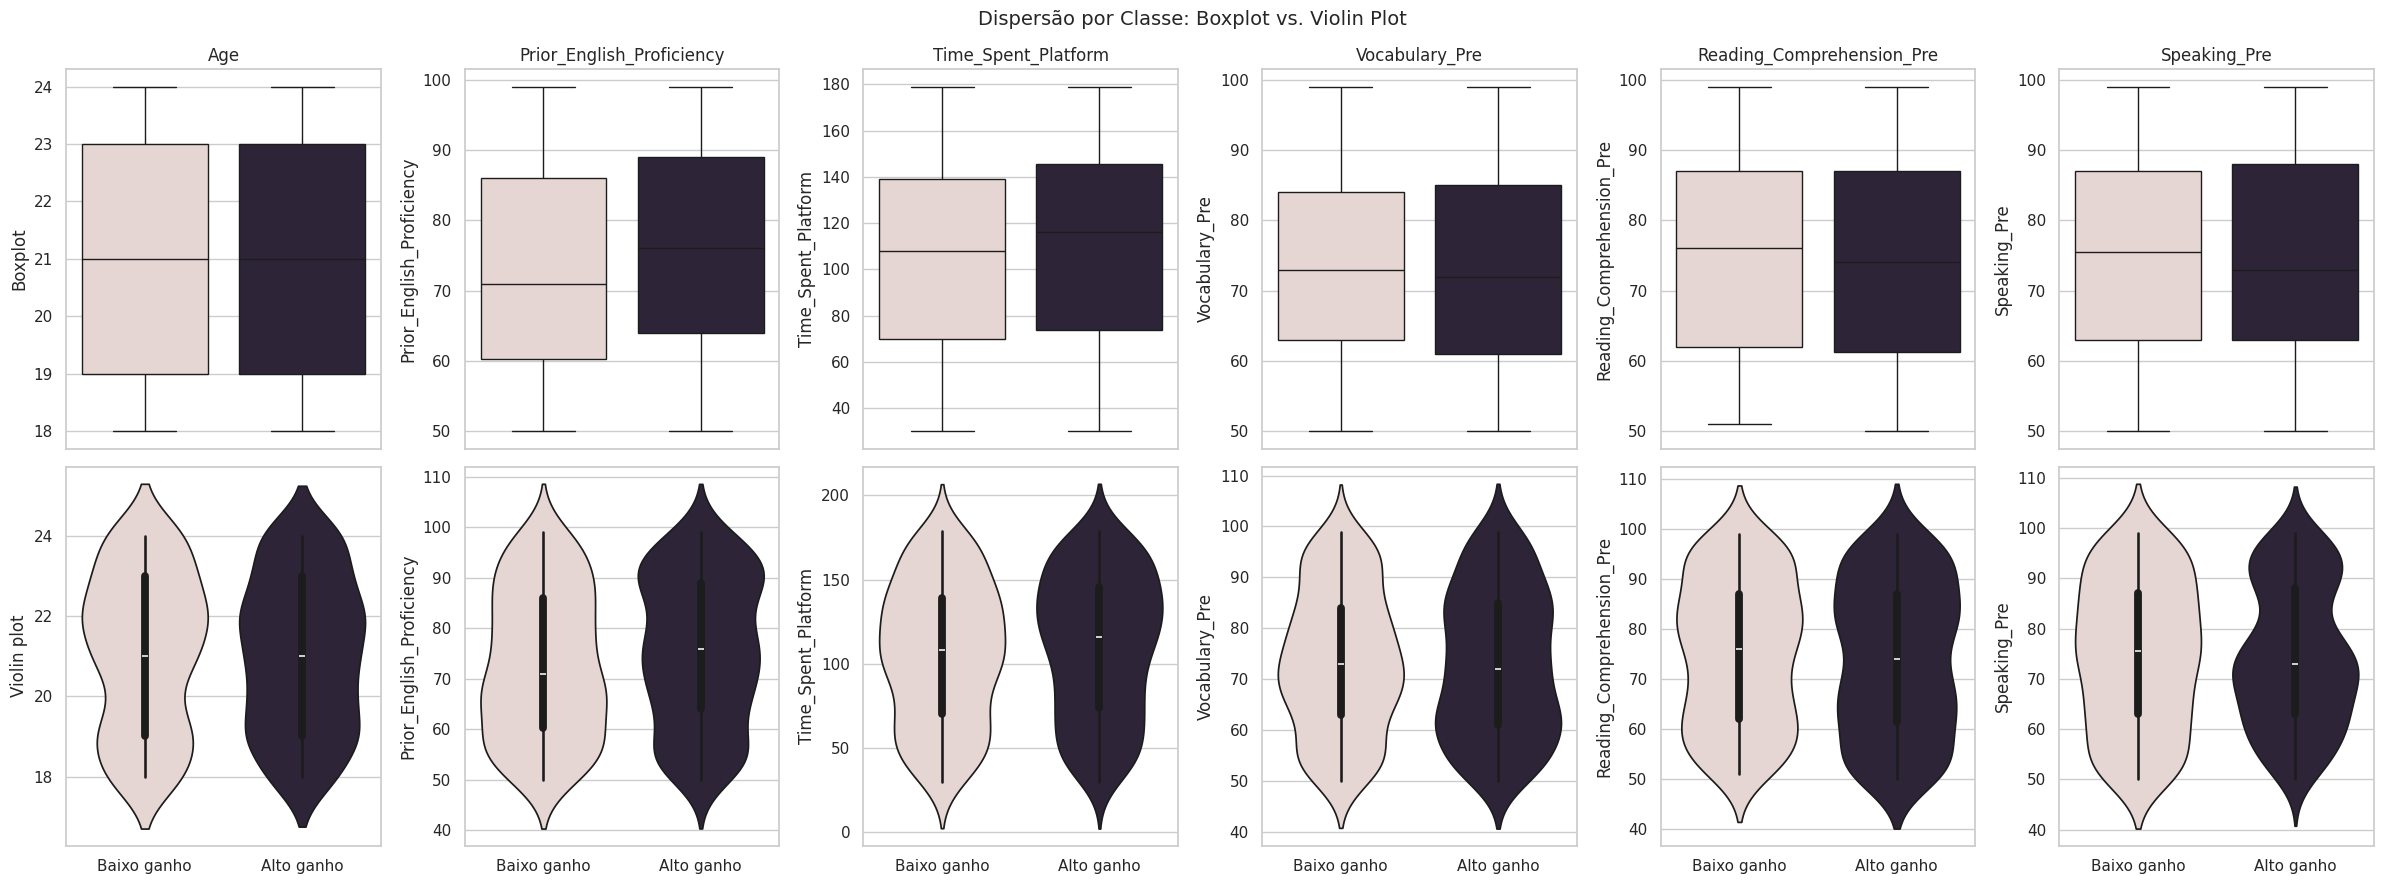

In [ ]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
display(dispersao.round(2))

### Boxplot e violin plot por classe

palette_classe = {"Baixo ganho": COR_CONTEXTO, "Alto ganho": COR_DESTAQUE}
ordem_classe = ["Baixo ganho", "Alto ganho"]

fig, axes = plt.subplots(2, len(VARS_PREDITORAS), figsize=(4 * len(VARS_PREDITORAS), 9), sharex="col")

for i, col in enumerate(VARS_PREDITORAS):
    sns.boxplot(data=df, x="desempenho", y=col, hue="desempenho", order=ordem_classe,
                palette=palette_classe, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="desempenho", y=col, hue="desempenho", order=ordem_classe,
                   palette=palette_classe, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Classe: Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre os grupos?

*Resposta*: Não, nos boxplots e nos violin plots, as medianas e as caixas ficam praticamente no mesmo nível nos dois grupos. A única com uma diferença pequena é `Prior_English_Proficiency` (mediana um pouco maior no alto ganho), que vou testar na análise bivariada. Os violin plots têm formato de "retângulo", de novo mostrando a distribuição uniforme.

## 4. Tratamento de Dados Ausentes, Outliers e Inconsistências

Com o retrato "antes" da Seção 3 já dá pra decidir o tratamento. Aqui **não há dados ausentes** (Seção 2), então esta seção fica com duas coisas: os **outliers** das variáveis quantitativas e uma **regra de domínio** que o dataset deveria respeitar (o ganho deveria ser nota depois menos nota antes). No fim, rodo a estatística descritiva de novo pra confirmar o efeito.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [ ]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
Age,13.0,29.0,0.0
Prior_English_Proficiency,23.0,127.0,0.0
Time_Spent_Platform,-32.0,248.0,0.0
Vocabulary_Pre,27.5,119.5,0.0
Reading_Comprehension_Pre,24.5,124.5,0.0
Speaking_Pre,27.0,123.0,0.0
Vocabulary_Post,31.0,119.0,0.0
Reading_Comprehension_Post,23.0,127.0,0.0
Speaking_Post,22.0,126.0,0.0
Vocabulary_Improvement,-31.0,49.0,0.0


Nenhuma das 12 variáveis teve outlier pela regra do IQR. Isso era esperado: numa distribuição uniforme os valores param de repente no mínimo e no máximo, então nenhum ponto fica longe o suficiente das caixas.

### Visualizando os Outliers

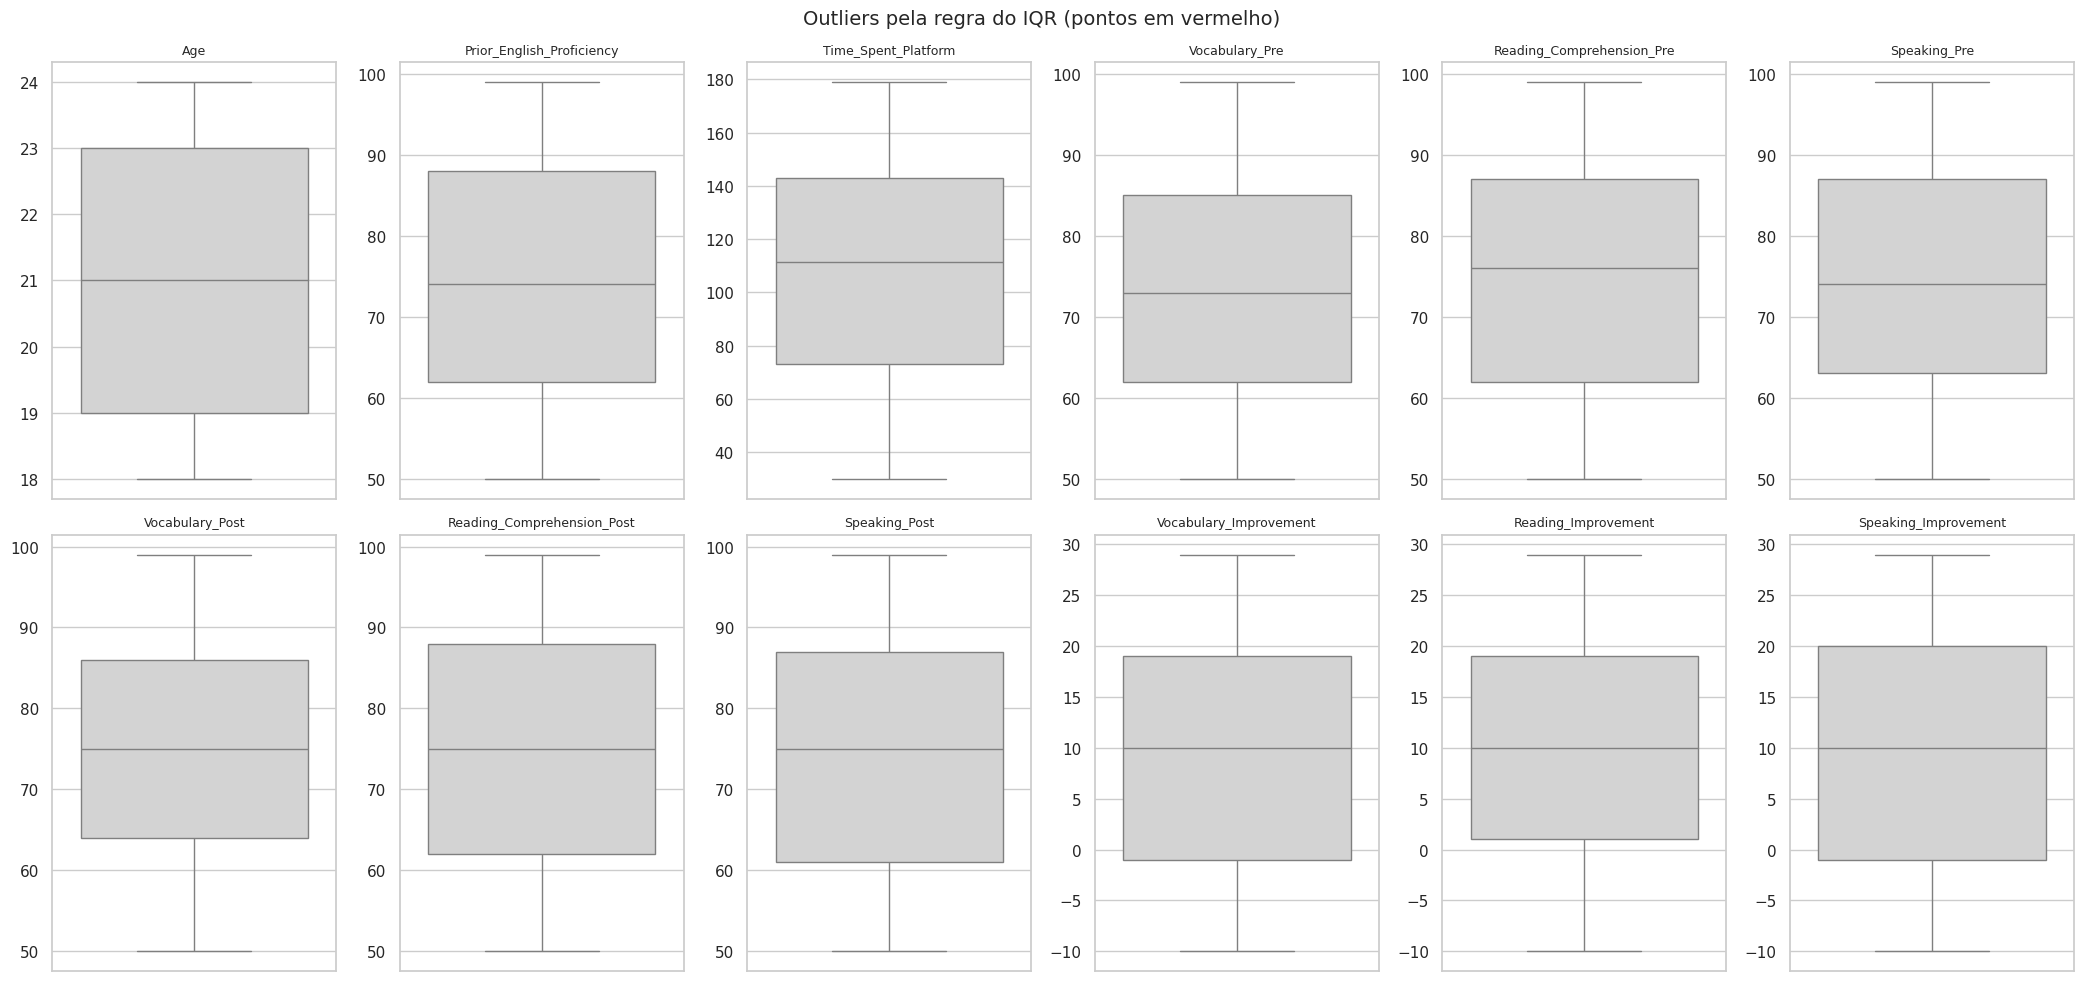

In [ ]:
n_cols = 6
n_linhas = int(np.ceil(len(VARS_QUANT) / n_cols))
fig, axes = plt.subplots(n_linhas, n_cols, figsize=(3.5 * n_cols, 5 * n_linhas))
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col, fontsize=9)
    axes[i].set_ylabel("")

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

*Resposta*: nenhum valor isolado é impossível (notas entre 50 e 99, idades entre 18 e 24, tempos positivos). O que poderia chamar atenção são os **ganhos negativos** (até -10), mas um aluno ir pior no pós-teste é plausível (cansaço, prova diferente, chute que deu certo no pré). Eles se encaixam como **estatísticos/legítimos**.

O problema de verdade não aparece em valores isolados, e sim na relação entre as colunas. Isso é o tipo **"de domínio: investigar"**, e é o que checo mais abaixo.

### Decidindo o Tratamento dos Dados Ausentes

A Seção 2 mostrou que não há nenhum `NaN` e nenhum valor "disfarçado" de ausente. Então nenhuma linha foi removida e nenhum valor foi imputado.

### Checando uma regra de domínio: o ganho bate com Pós − Pré?

Se `Vocabulary_Improvement` significa "quanto o aluno melhorou em vocabulário", ele deveria ser igual a `Vocabulary_Post - Vocabulary_Pre`. Dá pra testar isso linha a linha.

Antes de criar qualquer coluna nova, guardo uma cópia dos dados originais (`df_antes`) pra comparar depois.

In [ ]:
df_antes = df.copy()

COLS_GANHO_CALC = []
for pre, pos, ganho in zip(COLS_PRE, COLS_POS, COLS_GANHO):
    col_calc = f"{ganho}_calc"
    df[col_calc] = df[pos] - df[pre]
    COLS_GANHO_CALC.append(col_calc)

    bate = (df[col_calc] == df[ganho]).mean()
    print(f"{ganho}:")
    print(f"   igual a {pos} - {pre} em {bate:.1%} das linhas")
    print(f"   média informada = {df[ganho].mean():.2f} | média calculada (pós - pré) = {df[col_calc].mean():.2f}")

Vocabulary_Improvement:
   igual a Vocabulary_Post - Vocabulary_Pre em 1.4% das linhas
   média informada = 9.46 | média calculada (pós - pré) = 1.41
Reading_Improvement:
   igual a Reading_Comprehension_Post - Reading_Comprehension_Pre em 1.2% das linhas
   média informada = 9.84 | média calculada (pós - pré) = 0.05
Speaking_Improvement:
   igual a Speaking_Post - Speaking_Pre em 1.6% das linhas
   média informada = 9.73 | média calculada (pós - pré) = -0.18


**Pra discutir:** as colunas de ganho batem com a diferença entre as notas?

*Resposta*: Não, o ganho informado só é igual a Pós − Pré em cerca de 1% a 2% das linhas (o que dá pra explicar por coincidência). E a média do ganho informado fica perto de 10 pontos, enquanto a diferença real entre as médias das notas é perto de 0 em leitura e fala, e só ≈1,4 em vocabulário.

Então a base tem uma **inconsistência de domínio**: cada valor é plausível sozinho, mas as colunas não conversam entre si. Provavelmente as colunas de ganho foram geradas separadas das notas.

**Decisão:**

- **Manter** as colunas de ganho originais como alvo, porque é o que o dataset declara como target (o arquivo se chama `..._with_targets`);
- **Guardar** o ganho recalculado (`*_calc`) só pra comparação;
- **Registrar** isso como a principal limitação da análise;
- **Não remover linhas**, porque o problema está na base inteira e não em alunos específicos (removeria quase tudo).

### Decidindo o Tratamento dos Outliers

Como não há outlier pelo IQR e nenhum valor é impossível, **mantive todos os valores**. Não houve nada pra corrigir nem remover.

Na aula foi mostrado um log em `chol` pra reduzir a assimetria. Pra testar a opção **transformar**, fiz o mesmo em `Time_Spent_Platform`, mesmo sabendo que ela já não é assimétrica.

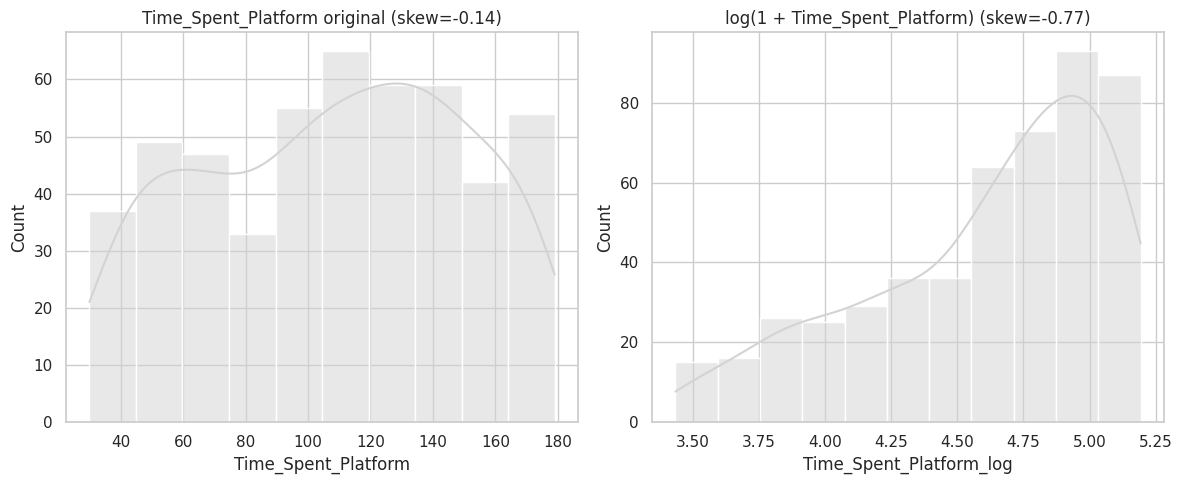

In [ ]:
df["Time_Spent_Platform_log"] = np.log1p(df["Time_Spent_Platform"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="Time_Spent_Platform", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"Time_Spent_Platform original (skew={df['Time_Spent_Platform'].skew():.2f})")

sns.histplot(data=df, x="Time_Spent_Platform_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + Time_Spent_Platform) (skew={df['Time_Spent_Platform_log'].skew():.2f})")

plt.tight_layout()
plt.show()

**Pra discutir:** a transformação logarítmica reduziu a assimetria?

*Resposta*: Não, piorou. O skew foi de cerca de -0,14 para cerca de -0,77. O log serve pra "encurtar" uma cauda longa à direita (como a do colesterol). Numa variável que já é simétrica, ele comprime os valores altos e acaba criando uma cauda à esquerda. Por isso **não uso** `Time_Spent_Platform_log` no resto da análise.

Conclusão do passo: nem todo outlier deve ser removido, e nem toda variável deve ser transformada. Depende do formato da distribuição.

## 5. Estatística Descritiva pt 2

Nenhuma linha foi removida e nenhum valor original foi alterado (só criei colunas novas). Mesmo assim, rodo a mesma bateria da Seção 3 pra **confirmar** isso, em vez de só assumir.

In [ ]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
Age,21.08,21.00,1.92,18.00,24.00,-0.08,-1.17
Prior_English_Proficiency,74.28,74.00,14.54,50.00,99.00,0.01,-1.22
Time_Spent_Platform,108.15,111.50,41.90,30.00,179.00,-0.14,-1.10
Vocabulary_Pre,73.29,73.00,14.04,50.00,99.00,0.11,-1.10
Reading_Comprehension_Pre,74.63,76.00,14.81,50.00,99.00,-0.04,-1.25
Speaking_Pre,74.63,74.00,14.27,50.00,99.00,0.04,-1.14
Vocabulary_Post,74.70,75.00,14.01,50.00,99.00,0.00,-1.08
Reading_Comprehension_Post,74.68,75.00,14.70,50.00,99.00,-0.00,-1.21
Speaking_Post,74.45,75.00,15.01,50.00,99.00,-0.02,-1.28
Vocabulary_Improvement,9.46,10.00,11.48,-10.00,29.00,0.03,-1.17


### Comparando "antes" x "depois"

In [ ]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
Age,-0.078,-0.078,-1.167,-1.167,0.0,0.0
Prior_English_Proficiency,0.009,0.009,-1.218,-1.218,0.0,0.0
Time_Spent_Platform,-0.138,-0.138,-1.099,-1.099,0.0,0.0
Vocabulary_Pre,0.106,0.106,-1.102,-1.102,0.0,0.0
Reading_Comprehension_Pre,-0.041,-0.041,-1.249,-1.249,0.0,0.0
Speaking_Pre,0.035,0.035,-1.140,-1.140,0.0,0.0
Vocabulary_Post,0.005,0.005,-1.082,-1.082,0.0,0.0
Reading_Comprehension_Post,-0.004,-0.004,-1.213,-1.213,0.0,0.0
Speaking_Post,-0.024,-0.024,-1.280,-1.280,0.0,0.0
Vocabulary_Improvement,0.030,0.030,-1.165,-1.165,0.0,0.0


**Pra discutir:** os valores mudaram?

*Resposta*: Não, todos os deltas de assimetria e curtose deram zero. Na aula a mudança foi pequena porque removeram ~2% das linhas; aqui é zero porque nada foi removido nem alterado. Isso serve como validação: os passos anteriores (criar o alvo, as colunas `_calc` e a coluna com log) não mexeram nos dados originais sem querer.

**O tempo na plataforma ainda rejeita normalidade?**

Mesmo Shapiro-Wilk da Seção 3, agora depois do tratamento.

In [ ]:
stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["Time_Spent_Platform"].dropna())
print(f"Shapiro-Wilk (antes)  | Time_Spent_Platform: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print(f"Shapiro-Wilk (depois) | Time_Spent_Platform: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")

Shapiro-Wilk (antes)  | Time_Spent_Platform: estatística=0.9601, p-valor=2.169e-10
Shapiro-Wilk (depois) | Time_Spent_Platform: estatística=0.9601, p-valor=2.169e-10


Estatística e p-valor idênticos antes e depois, como esperado, já que a coluna não mudou.

**Visualizando a comparação que realmente importa: ganho informado x ganho recalculado**

Na aula foram sobrepostas as curvas "antes" e "depois" de `chol` e `oldpeak`. Aqui isso daria duas curvas idênticas, então não traria informação. A comparação útil é outra: o ganho **informado** pelo dataset (rosa) contra o ganho **recalculado** como Pós − Pré (roxo), em cada habilidade.

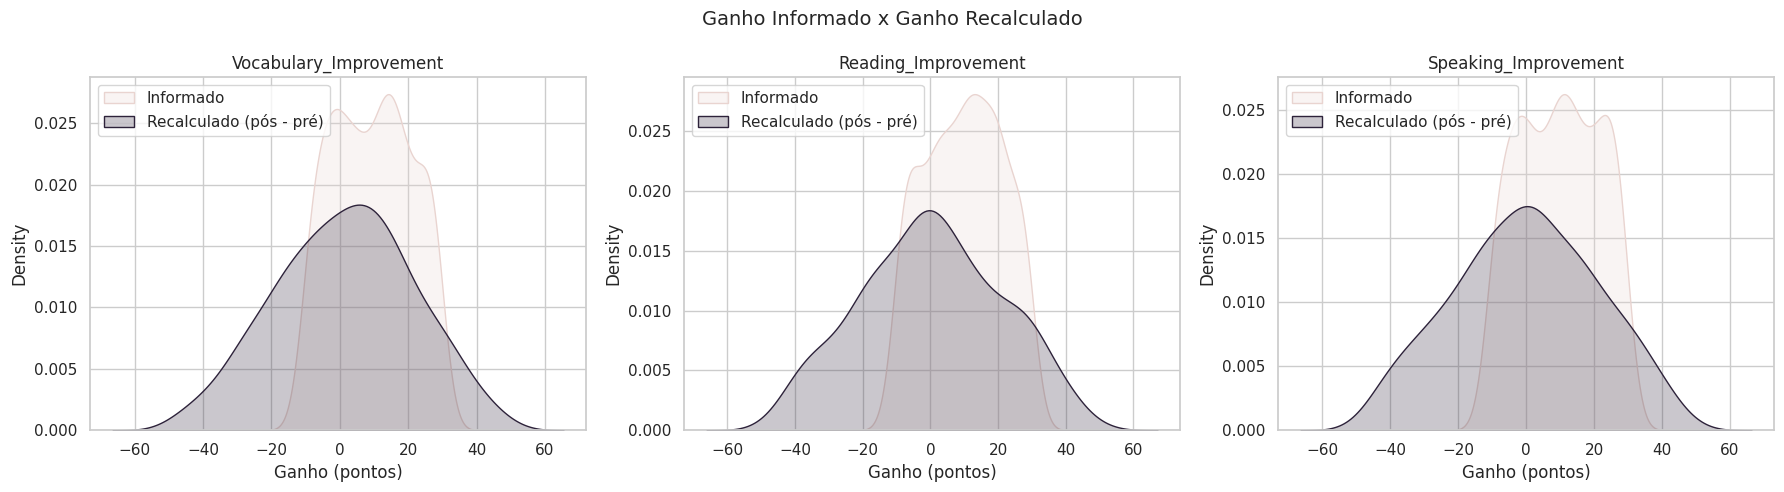

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, ganho, calc in zip(axes, COLS_GANHO, COLS_GANHO_CALC):
    sns.kdeplot(df_antes[ganho], color=COR_CONTEXTO, fill=True, label="Informado", ax=ax)
    sns.kdeplot(df[calc], color=COR_DESTAQUE, fill=True, label="Recalculado (pós - pré)", ax=ax)
    ax.set_title(ganho)
    ax.set_xlabel("Ganho (pontos)")
    ax.legend()

fig.suptitle("Ganho Informado x Ganho Recalculado", fontsize=14)
plt.tight_layout()
plt.show()

A figura deixa a inconsistência bem visível: o ganho informado fica entre -10 e 29, com centro perto de 10, enquanto a diferença real das notas vai de cerca de -49 a 49, com centro perto de 0 e formato de "triângulo" (que é o que acontece quando se subtrai duas uniformes). As duas distribuições não têm nada a ver uma com a outra.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora avalio frequência e desbalanceamento das variáveis qualitativas.

#### Frequências absolutas e relativas

In [ ]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))


--- Gender ---
        absoluta  relativa
Gender                    
Male         253     0.506
Female       247     0.494

--- Learning_Style ---
                absoluta  relativa
Learning_Style                    
Kinesthetic          179     0.358
Visual               163     0.326
Auditory             158     0.316

--- Motivation_Level ---
                  absoluta  relativa
Motivation_Level                    
3                      130     0.260
4                      126     0.252
1                      124     0.248
2                      120     0.240

--- Platform_Usage_Frequency ---
                          absoluta  relativa
Platform_Usage_Frequency                    
3                               97     0.194
4                               96     0.192
2                               92     0.184
1                               86     0.172
5                               65     0.130
6                               64     0.128


#### Visualizando as frequências

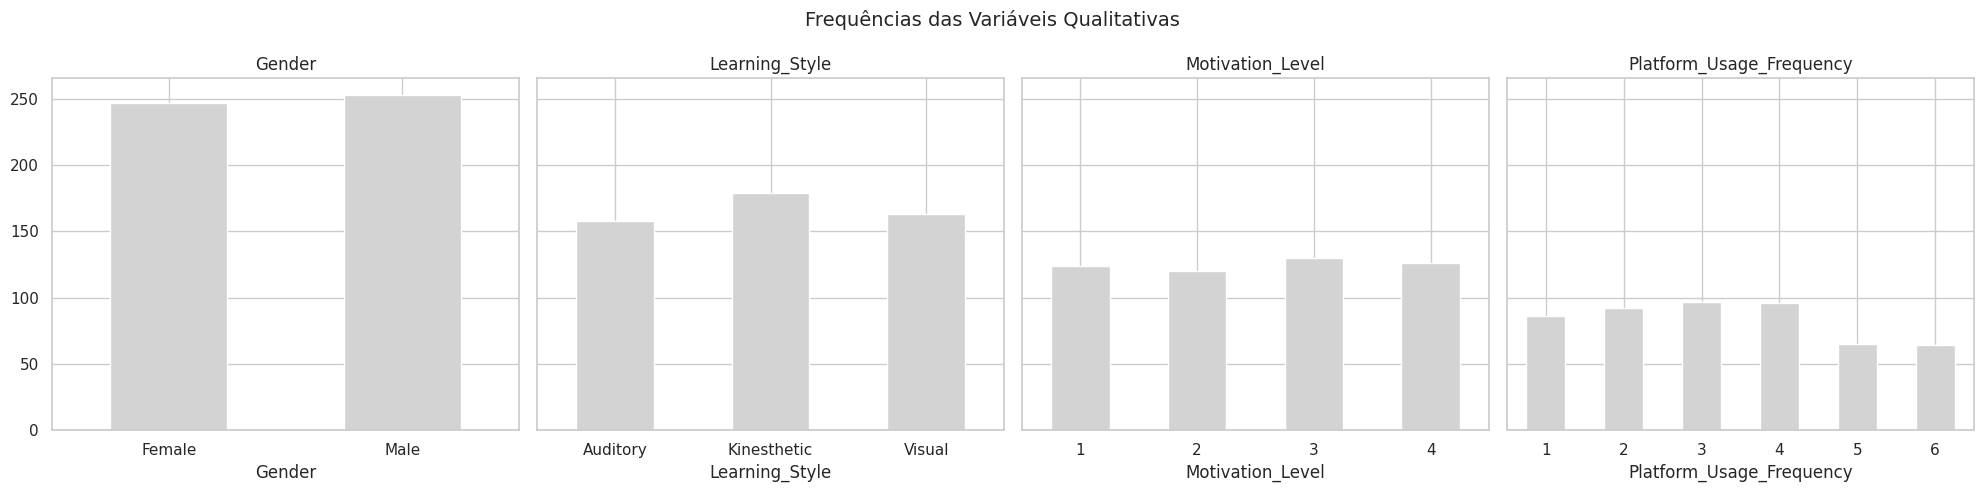

In [ ]:
fig, axes = plt.subplots(1, len(VARS_QUALI), figsize=(20, 5), sharey=True)

for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=0)

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase tudo)?

*Resposta*: Não. `Gender`, `Learning_Style` e `Motivation_Level` têm categorias com contagens bem parecidas. A única com alguma diferença é `Platform_Usage_Frequency`: os níveis 5 e 6 têm cerca de 65 alunos cada, enquanto os níveis 1 a 4 têm entre 86 e 97. Mesmo assim nenhuma categoria é tão pequena a ponto de atrapalhar os cruzamentos.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento**: # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada**: 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Aplico as duas em todas as qualitativas, incluindo o próprio alvo `desempenho`.

In [ ]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI + ["desempenho"]
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
Gender,2.0,1.02,1.000
Learning_Style,3.0,1.13,0.999
Motivation_Level,4.0,1.08,1.000
Platform_Usage_Frequency,6.0,1.52,0.992
desempenho,2.0,1.03,1.000


**Pra discutir:** alguma variável tem entropia perto de 0? E o alvo `desempenho`?

*Resposta*: Nenhuma. Todas ficaram com entropia perto de 1. A maior razão de desbalanceamento é a de `Platform_Usage_Frequency` (≈1,5), pelo motivo visto no gráfico acima. O alvo `desempenho` ficou com razão ≈1,03, mas isso **não é uma descoberta sobre os dados**: é consequência de eu ter usado a mediana como corte na Seção 1.

### Análise Bivariada

Agora avalio como as variáveis se relacionam entre si e com o alvo `desempenho`.

#### Quantitativa x Quantitativa: Correlação

Três técnicas principais:
* **Pearson** (linear, sensível a outliers, pressupõe normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como nenhuma variável passou no Shapiro-Wilk, Spearman é a escolha mais segura, mas calculo as três pra comparar.

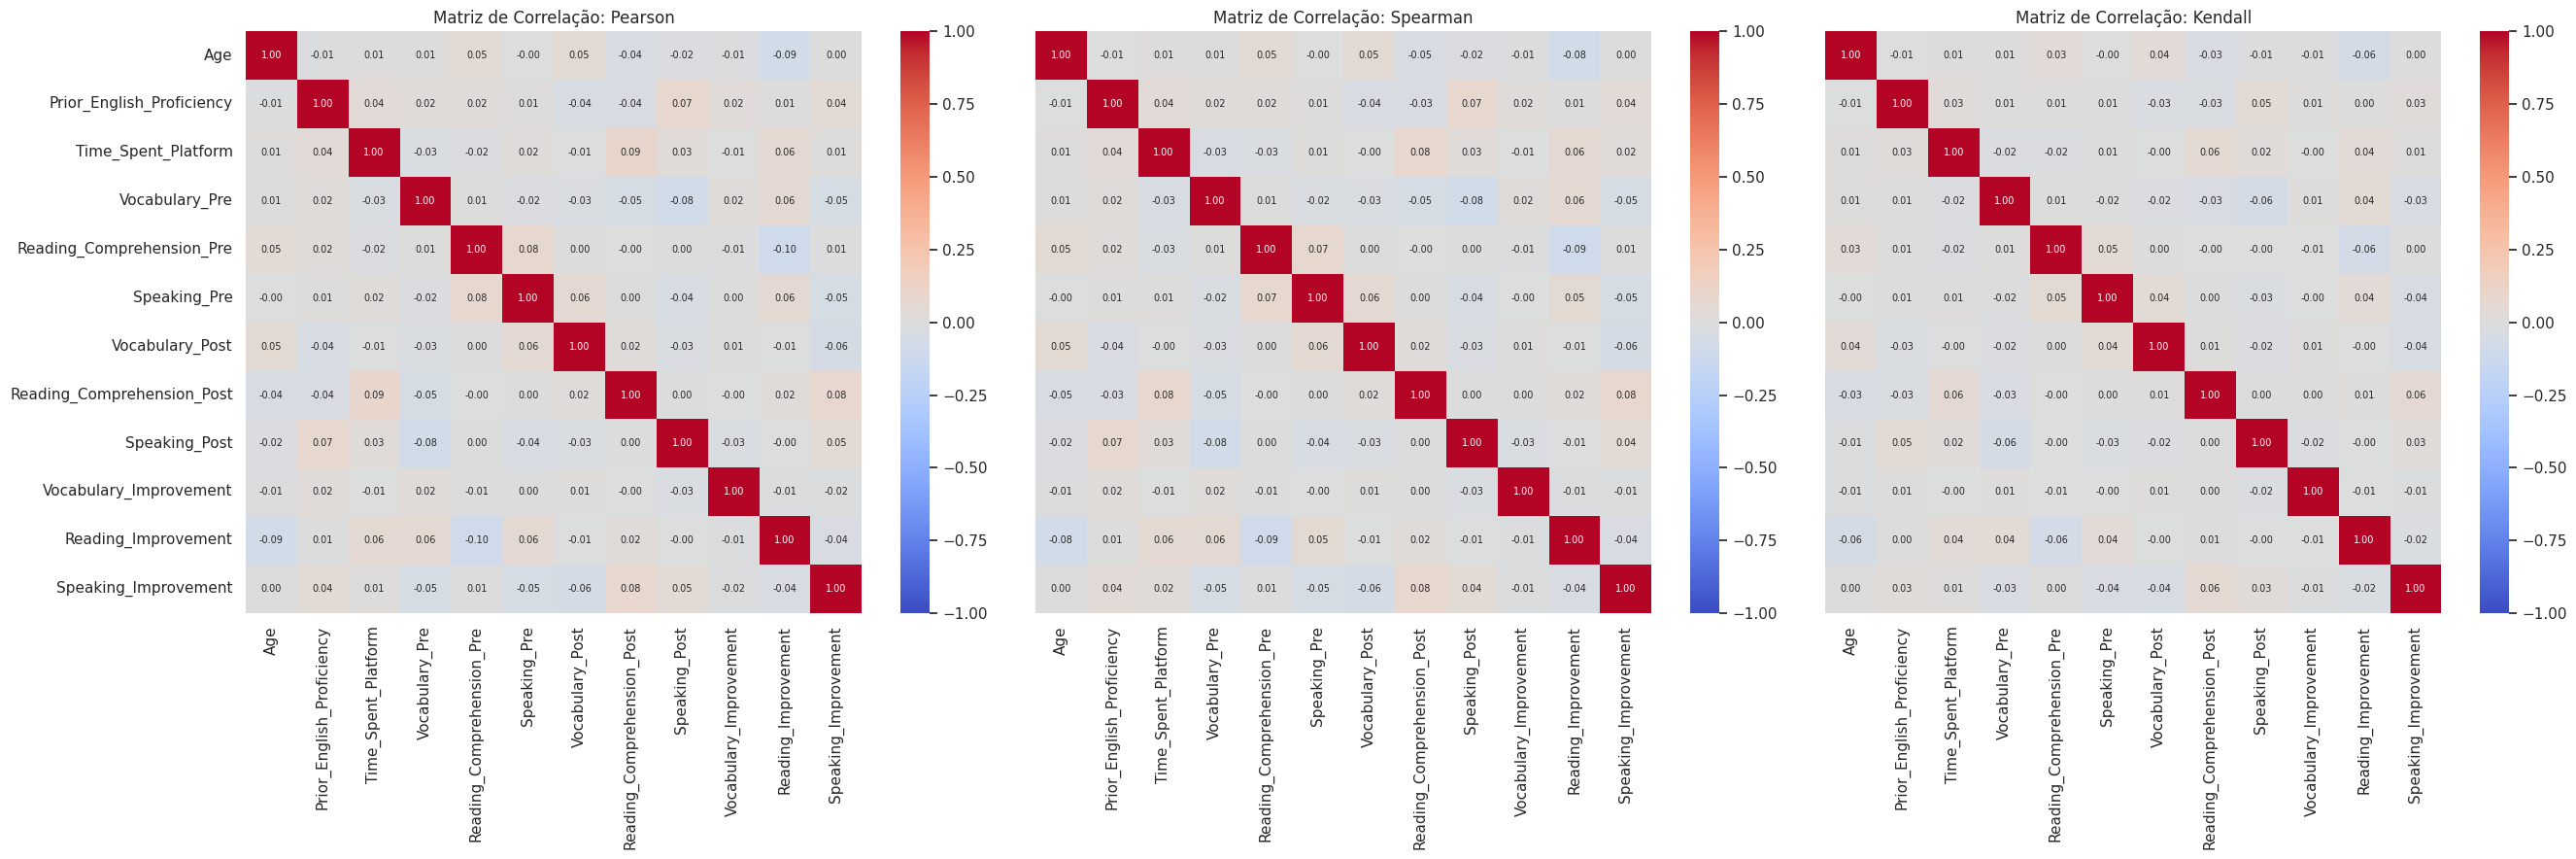

In [ ]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1, 3, figsize=(27, 9), sharey=True)
for eixo, matriz, nome in zip(ax, [corr_pearson, corr_spearman, corr_kendall], ["Pearson", "Spearman", "Kendall"]):
    sns.heatmap(matriz, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
                annot_kws={"size": 7}, ax=eixo)
    eixo.set_title(f"Matriz de Correlação: {nome}")
plt.tight_layout()
plt.show()

Todas as correlações fora da diagonal ficaram muito fracas, abaixo de 0,10 em módulo nos três métodos. Em dados reais eu esperaria, por exemplo, que a proficiência prévia se correlacionasse com as notas pré, que a nota pré de uma habilidade se correlacionasse com a nota pós da mesma habilidade, e que mais tempo de plataforma tivesse alguma relação com mais ganho. Nada disso aparece, o que reforça a ideia de que cada coluna foi gerada de forma independente.

Como a matriz é simétrica (o triângulo de cima é igual ao de baixo), dá pra mostrar só metade dela:

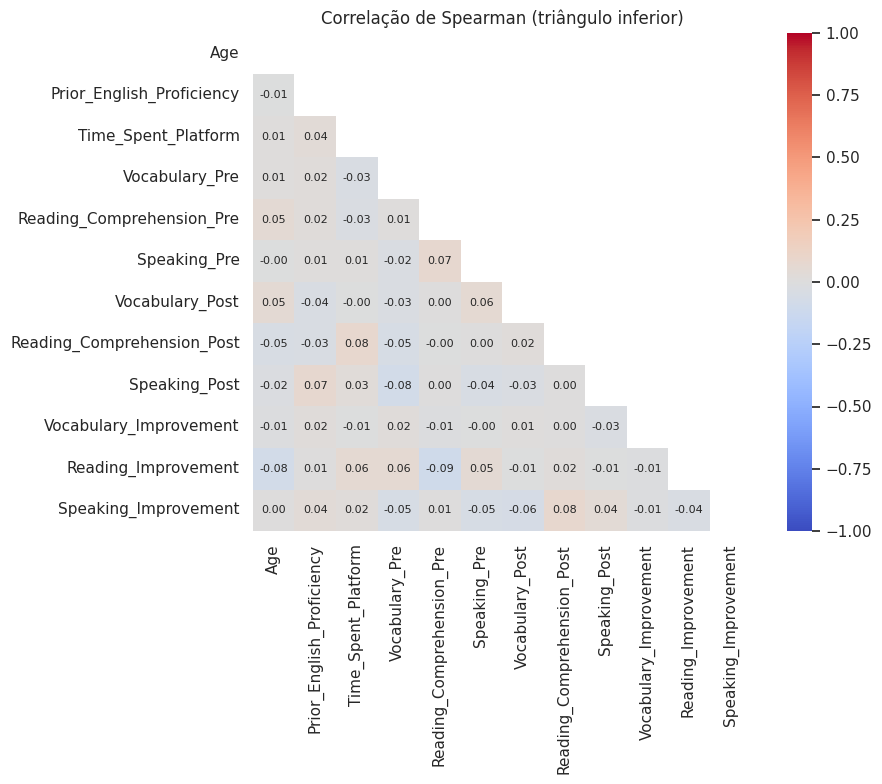

In [ ]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(10, 8))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1,
            annot_kws={"size": 8})
plt.grid(False)
plt.title("Correlação de Spearman (triângulo inferior)")
plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis? Se sim, seria sinal de relação não-linear que o Spearman captura e o Pearson não.

*Resposta*: Não, a maior diferença entre Pearson e Spearman em qualquer par ficou abaixo de 0,01. Como praticamente não existe relação nenhuma (nem linear, nem não-linear), os dois métodos dão quase o mesmo número.

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhi `Vocabulary_Pre` x `Vocabulary_Post` por um motivo de domínio (como a aula fez com `age` x `thalach`): quem começa sabendo mais vocabulário normalmente termina sabendo mais. É o par em que uma relação "deveria" aparecer, se os dados fossem reais.

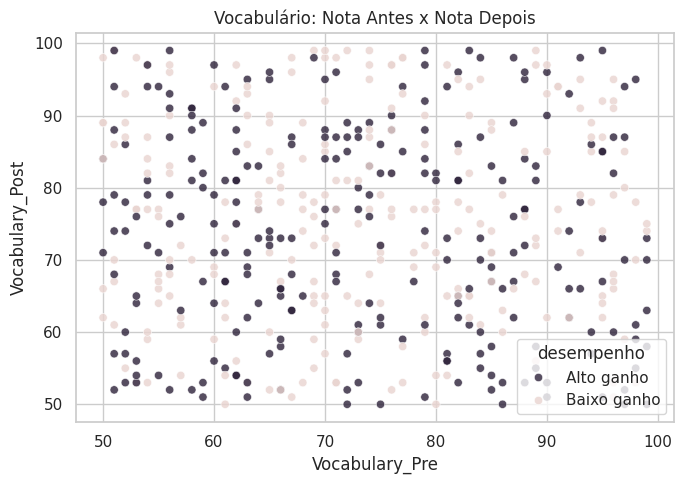

In [ ]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Vocabulary_Pre", y="Vocabulary_Post", hue="desempenho",
                palette={"Baixo ganho": COR_CONTEXTO, "Alto ganho": COR_DESTAQUE}, alpha=0.8)
plt.title("Vocabulário: Nota Antes x Nota Depois")
plt.xlabel("Vocabulary_Pre")
plt.ylabel("Vocabulary_Post")
plt.tight_layout()
plt.show()

**Pra discutir:** existe uma tendência visível (quanto maior a nota pré, maior a nota pós)? As duas classes ocupam regiões diferentes do gráfico?

*Resposta*: Não há tendência. Os pontos formam uma "nuvem quadrada" preenchendo todo o espaço de 50 a 99 nos dois eixos (a correlação de Spearman entre as duas é ≈ -0,03). As duas cores estão completamente misturadas, então as notas de vocabulário não ajudam a separar alto e baixo ganho, o que também confirma que o ganho informado não depende das notas.

#### Quantitativa x Qualitativa: Comparando Grupos

**T-Test** (2 grupos) e **ANOVA** (3+ grupos) são paramétricos e pressupõem normalidade dentro de cada grupo. Como nenhuma variável preditora passou no Shapiro-Wilk, os resultados principais são os **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test e **Kruskal-Wallis** no lugar da ANOVA. Calculo os dois lado a lado pra comparar.

In [ ]:
resultados_comparacao = []
for col in VARS_PREDITORAS:
    grupo_baixo = df.loc[df["desempenho"] == "Baixo ganho", col]
    grupo_alto = df.loc[df["desempenho"] == "Alto ganho", col]

    stat_t, p_t = stats.ttest_ind(grupo_baixo, grupo_alto, equal_var=False)  # Welch (paramétrico)
    stat_u, p_u = stats.mannwhitneyu(grupo_baixo, grupo_alto)                 # não-paramétrico

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_ttest": round(p_t, 5),
        "p_valor_mannwhitney": round(p_u, 5),
        "concordam": (p_t < 0.05) == (p_u < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")

,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,
Age,0.66507,0.63572,True
Prior_English_Proficiency,0.04685,0.04744,True
Time_Spent_Platform,0.24891,0.23391,True
Vocabulary_Pre,0.68062,0.66285,True
Reading_Comprehension_Pre,0.34176,0.35180,True
Speaking_Pre,0.91036,0.84436,True


**Pra discutir:** os dois testes concordam? Quando divergem, qual priorizar?

*Resposta*: concordaram em todas as variáveis. Quase todas deram p-valor bem acima de 0,05, ou seja, sem diferença entre os grupos. A exceção é `Prior_English_Proficiency`, com p ≈ 0,047 nos dois testes (a mediana é 76 no alto ganho e 71 no baixo ganho).

Eu não trataria isso como uma descoberta forte, por dois motivos:
1. O p-valor ficou colado no limite de 0,05, e eu fiz 6 testes. Com 6 tentativas, é relativamente comum um deles dar "significativo" só por acaso.
2. A correlação entre proficiência prévia e as colunas de ganho é praticamente zero (Seção anterior), então não há uma relação consistente por trás.

Se os testes divergissem, eu priorizaria o **Mann-Whitney**, porque ele respeita a premissa que os dados realmente têm (não são normais).

*Exemplo com 3+ grupos: ANOVA x Kruskal-Wallis*

Na aula foi usado `cp` (tipo de dor no peito). Aqui uso `Learning_Style`, que tem 3 categorias. A pergunta é: **o ganho médio muda conforme o estilo de aprendizagem?** Se a plataforma favorecesse algum estilo (por exemplo, muito conteúdo visual), isso apareceria aqui.

ANOVA          | ganho_medio entre estilos de aprendizagem: estatística=0.418, p-valor=0.65864
Kruskal-Wallis | ganho_medio entre estilos de aprendizagem: estatística=0.920, p-valor=0.63133


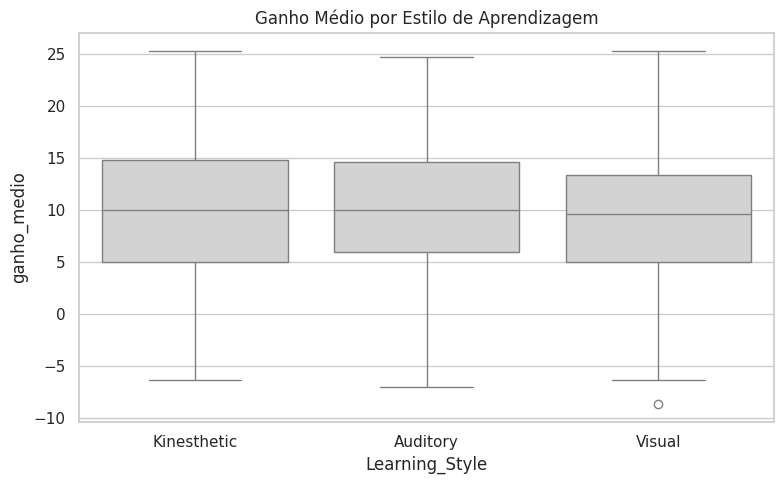

In [ ]:
grupos_estilo = [grupo["ganho_medio"].values for _, grupo in df.groupby("Learning_Style")]

stat_anova, p_anova = stats.f_oneway(*grupos_estilo)   # paramétrico
stat_kw, p_kw = stats.kruskal(*grupos_estilo)          # não-paramétrico

print(f"ANOVA          | ganho_medio entre estilos de aprendizagem: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
print(f"Kruskal-Wallis | ganho_medio entre estilos de aprendizagem: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Learning_Style", y="ganho_medio", color=COR_NEUTRA)
plt.title("Ganho Médio por Estilo de Aprendizagem")
plt.tight_layout()
plt.show()

**Pra discutir:** o Kruskal-Wallis indica diferença entre pelo menos um estilo?

*Resposta*: Não. Os dois testes deram p-valor acima de 0,6, e no boxplot as medianas dos três estilos ficam em torno de 10. Pelos dados, a plataforma não favorece nenhum estilo de aprendizagem. Aqui a variável comparada é o `ganho_medio`, que não rejeitou a normalidade na Seção 3, então neste caso a ANOVA também seria aceitável. Como os dois testes concordam, a conclusão é a mesma.

#### Qualitativa x Qualitativa

Uso o **Qui-Quadrado** pra testar se duas variáveis categóricas são independentes. Na aula foi `thal` x `doenca_cardiaca`. Aqui escolhi `Motivation_Level` x `desempenho`, porque é a hipótese mais intuitiva do dataset: alunos mais motivados deveriam ganhar mais.

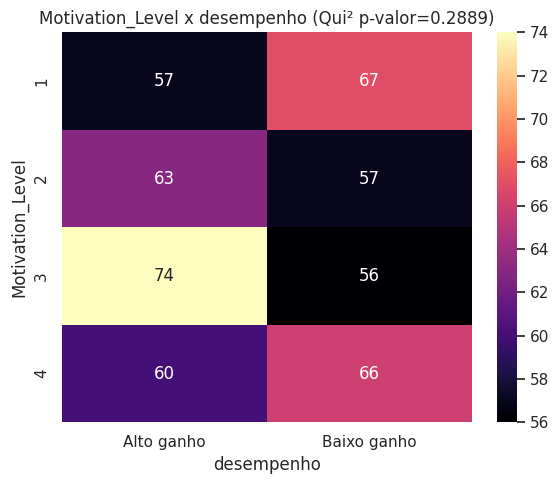

In [ ]:
contingencia_motivacao = pd.crosstab(df["Motivation_Level"], df["desempenho"])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_motivacao)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(contingencia_motivacao, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"Motivation_Level x desempenho (Qui² p-valor={p_chi2:.4g})")
plt.tight_layout()
plt.show()

**Pra discutir:** o p-valor do Qui-Quadrado indica que motivação e desempenho são independentes, ou há associação significativa?

*Resposta*: o p-valor ficou em torno de 0,29, então não dá pra rejeitar a independência. No heatmap, o nível 3 até tem um pouco mais de alunos com alto ganho (74 contra 56), mas o nível 4, que seria o mais motivado, não segue esse padrão. Ou seja, não aparece aquela relação "mais motivação, mais ganho". Como os dados parecem sintéticos, o mais provável é que essa relação simplesmente não foi colocada na hora de gerar a base, e não que motivação não importe na vida real.

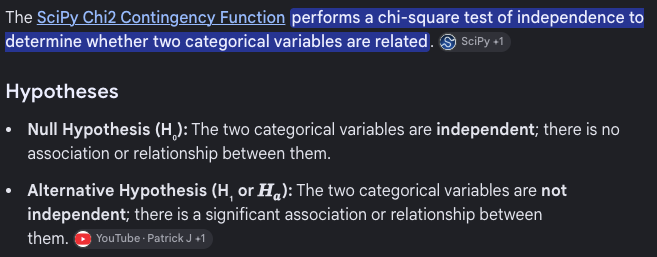

#### Avaliação de Fairness

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta central em **fairness** é: o desfecho se comporta igual em diferentes subgrupos de atributos sensíveis? Na aula foram usados sexo e faixa etária de pacientes. No contexto de uma plataforma de ensino, a pergunta vira: **a plataforma beneficia todos os grupos da mesma forma?** Se alunos de um gênero ou de uma faixa etária ganham sistematicamente menos, isso pode indicar um problema no conteúdo ou um viés em quem participou do estudo.

Como todos os alunos têm entre 18 e 24 anos, as faixas etárias precisam ser estreitas (18-19, 20-21 e 22-24). Na aula foi preciso criar o `sexo_label` convertendo 0/1 em Feminino/Masculino; aqui não, porque `Gender` já vem como texto. Só copio a coluna com um nome em português.

In [ ]:
df["genero_label"] = df["Gender"]
df["faixa_etaria"] = pd.cut(df["Age"], bins=[17, 19, 21, 24], labels=["18-19", "20-21", "22-24"])

print("Desbalanceamento | gênero:")
print(metrica_desbalanceamento(df["genero_label"]))
print("\nDesbalanceamento | faixa etária:")
print(metrica_desbalanceamento(df["faixa_etaria"]))

Desbalanceamento | gênero:
n_classes                 2.00
razao_desbalanceamento    1.02
entropia_normalizada      1.00
dtype: float64

Desbalanceamento | faixa etária:
n_classes                 3.000
razao_desbalanceamento    1.690
entropia_normalizada      0.971
dtype: float64


Gênero está equilibrado. A faixa etária tem razão ≈1,7 porque o grupo 22-24 junta três idades (228 alunos) enquanto os outros juntam duas (cerca de 135 cada). Não é um problema, cada faixa ainda tem bastante gente.

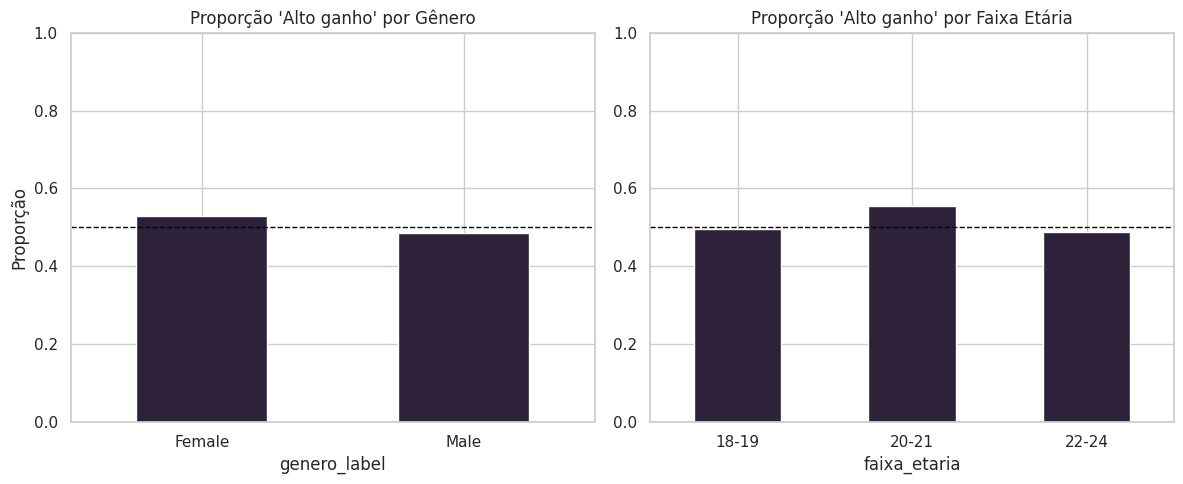

In [ ]:
prop_por_genero = pd.crosstab(df["genero_label"], df["desempenho"], normalize="index").round(3)
prop_por_faixa = pd.crosstab(df["faixa_etaria"], df["desempenho"], normalize="index").round(3)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

prop_por_genero["Alto ganho"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[0])
axes[0].set_title("Proporção 'Alto ganho' por Gênero")
axes[0].set_ylabel("Proporção")
axes[0].set_ylim(0, 1)
axes[0].axhline(0.5, color="black", linestyle="--", linewidth=1)
axes[0].tick_params(axis="x", rotation=0)

prop_por_faixa["Alto ganho"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
axes[1].set_title("Proporção 'Alto ganho' por Faixa Etária")
axes[1].set_ylim(0, 1)
axes[1].axhline(0.5, color="black", linestyle="--", linewidth=1)
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Pra discutir:** a linha tracejada marca 50%, que é a proporção de "Alto ganho" na base inteira (por causa do corte na mediana). Algum grupo se afasta muito dela?

*Resposta*: Não muito. Entre os gêneros, as alunas ficaram com ≈53% de alto ganho e os alunos com ≈49%. Entre as faixas etárias, 20-21 anos ficou com ≈56% e as outras duas perto de 50%. São diferenças de poucos pontos, que podem ser só variação normal de amostra. O teste abaixo ajuda a decidir.

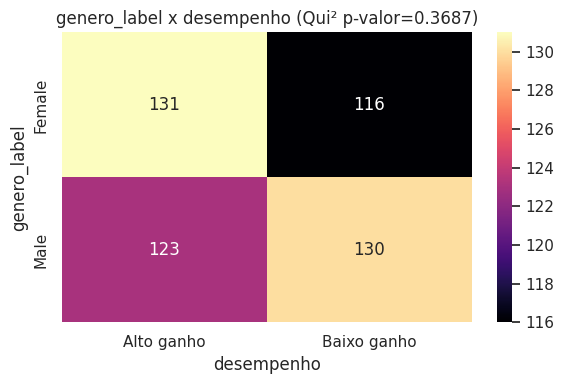

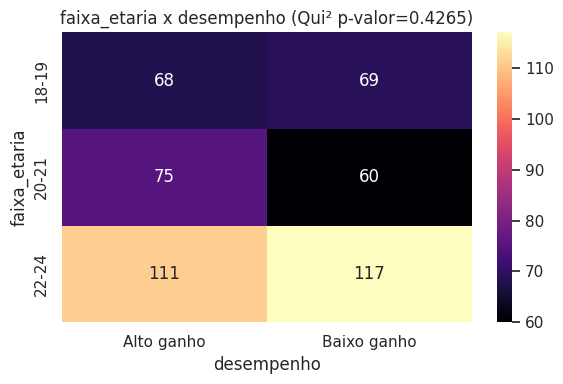

In [ ]:
for atributo in ["genero_label", "faixa_etaria"]:
    contingencia = pd.crosstab(df[atributo], df["desempenho"])
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"{atributo} x desempenho (Qui² p-valor={p_valor:.4g})")
    plt.tight_layout()
    plt.show()

    if (esperado < 5).any():
        print(f"Atenção: {atributo} tem célula com frequência esperada < 5. O Qui² fica pouco confiável.")

**Pra discutir:** o Qui-Quadrado confirma associação significativa entre gênero/faixa etária e o desempenho?

*Resposta*: Não. Os p-valores ficaram em torno de 0,37 (gênero) e 0,43 (faixa etária), e nenhuma célula teve frequência esperada menor que 5, então o teste é confiável aqui. Pelos dados, a plataforma tem resultado parecido pra todos os grupos.

Mesmo quando um teste dá significativo, ele só aponta *que* existe associação, não *por que* ela existe. E aqui vale uma ressalva extra: como a base parece sintética, a "justiça" que aparece pode ser só consequência de as colunas terem sido geradas de forma independente, e não uma prova de que uma plataforma real trataria todos igual.

#### Outliers bivariados

Aqui procuro combinações incomuns entre o **esforço** (tempo na plataforma) e o **resultado** (ganho médio). Um aluno com muito tempo de uso e ganho negativo, por exemplo, pode não parecer outlier em nenhuma das duas variáveis sozinhas, mas é um caso estranho quando olho as duas juntas.

Na aula os pontos foram coloridos por classe. Aqui não pinto, porque a classe foi definida pelo próprio ganho médio (eixo Y): a cor só mostraria uma linha horizontal na mediana, sem informação nova.

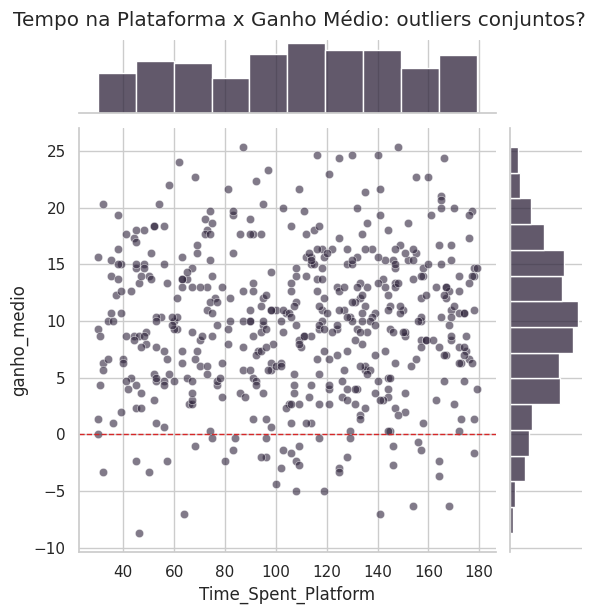

Spearman tempo x ganho médio: r = 0.040 (p = 0.369)
Alunos com mais de 150 de tempo na plataforma e ganho médio negativo: 7


In [ ]:
g = sns.jointplot(data=df, x="Time_Spent_Platform", y="ganho_medio",
                  color=COR_DESTAQUE, alpha=0.6, height=6)
g.ax_joint.axhline(0, color=COR_ALERTA, linestyle="--", linewidth=1)
plt.suptitle("Tempo na Plataforma x Ganho Médio: outliers conjuntos?", y=1.02)
plt.show()

rho, p_rho = stats.spearmanr(df["Time_Spent_Platform"], df["ganho_medio"])
n_casos = ((df["Time_Spent_Platform"] > 150) & (df["ganho_medio"] < 0)).sum()
print(f"Spearman tempo x ganho médio: r = {rho:.3f} (p = {p_rho:.3f})")
print(f"Alunos com mais de 150 de tempo na plataforma e ganho médio negativo: {n_casos}")

**Pra discutir:** existe algum ponto que não parecia outlier nos histogramas, mas se destaca pela combinação das duas variáveis?

*Resposta*: Existem alguns casos "estranhos" do ponto de vista do domínio, como 7 alunos que passaram mais de 150 de tempo na plataforma e mesmo assim tiveram ganho médio negativo (abaixo da linha vermelha). Mas eles não se destacam visualmente, porque ficam no meio de uma nuvem que preenche todo o retângulo. Não há tendência de "mais tempo, mais ganho" (Spearman ≈ 0,04, p ≈ 0,37), então não existe um padrão do qual esses pontos estariam fugindo. Por isso não os considero outliers bivariados e mantive todos.

#### Análise Multivariada

##### Matriz de Correlação

Aqui incluo também o `ganho_medio`, pra ver a relação dele com todas as outras variáveis quantitativas.

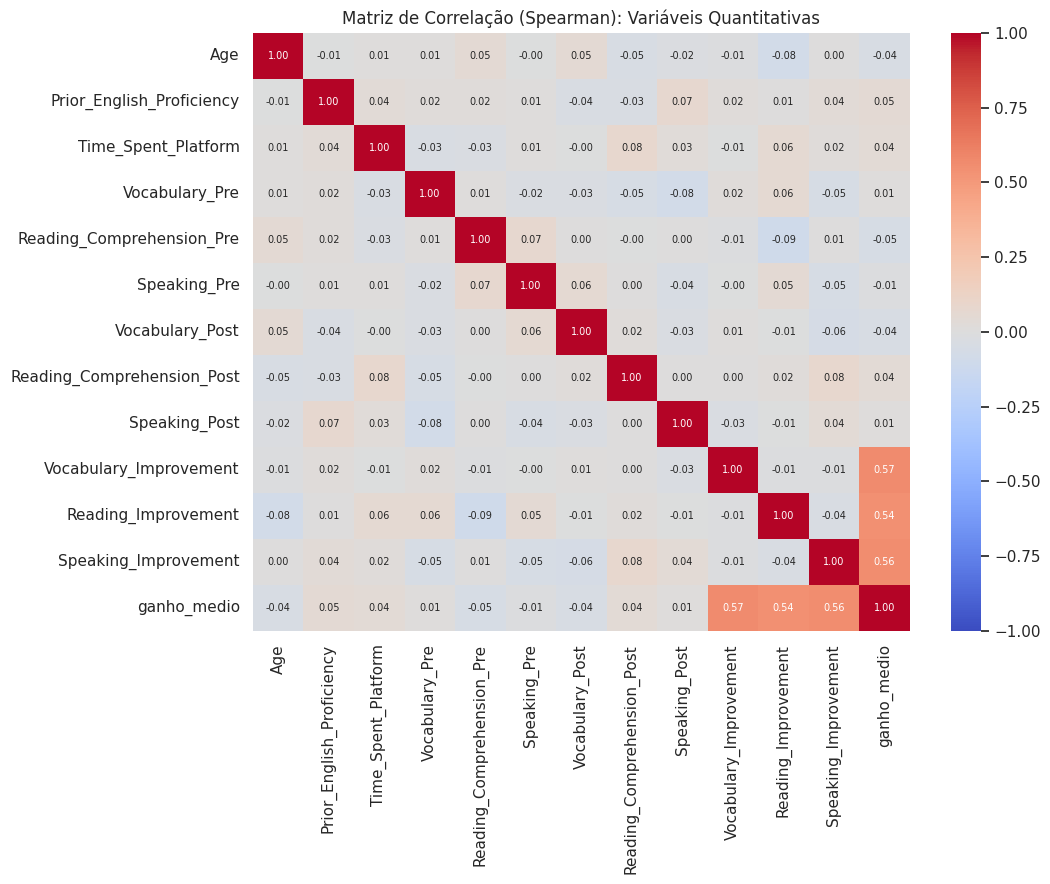

In [ ]:
VARS_MULTI = VARS_QUANT + ["ganho_medio"]

plt.figure(figsize=(11, 9))
sns.heatmap(df[VARS_MULTI].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Matriz de Correlação (Spearman): Variáveis Quantitativas")
plt.tight_layout()
plt.show()

**Como interpretar:**

*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*   |r| > 0.7 ~ forte.

Alguma correlação é forte o suficiente pra sugerir redundância entre variáveis?

*Resposta*: as únicas correlações que não são fracas são as do `ganho_medio` com as três colunas de ganho (entre ≈0,54 e ≈0,57, moderadas). Mas isso acontece **por construção**, já que ele é a média delas, então não é uma descoberta. Fora isso, tudo é fraco e nenhuma variável é redundante com outra.

##### Correlograma

Pra manter o gráfico legível, uso só as variáveis preditoras e o `ganho_medio`. Com as 12 quantitativas seriam 144 painéis. Também troquei o cálculo do círculo de Pearson (`np.corrcoef`) para Spearman, pra ficar coerente com o heatmap acima.

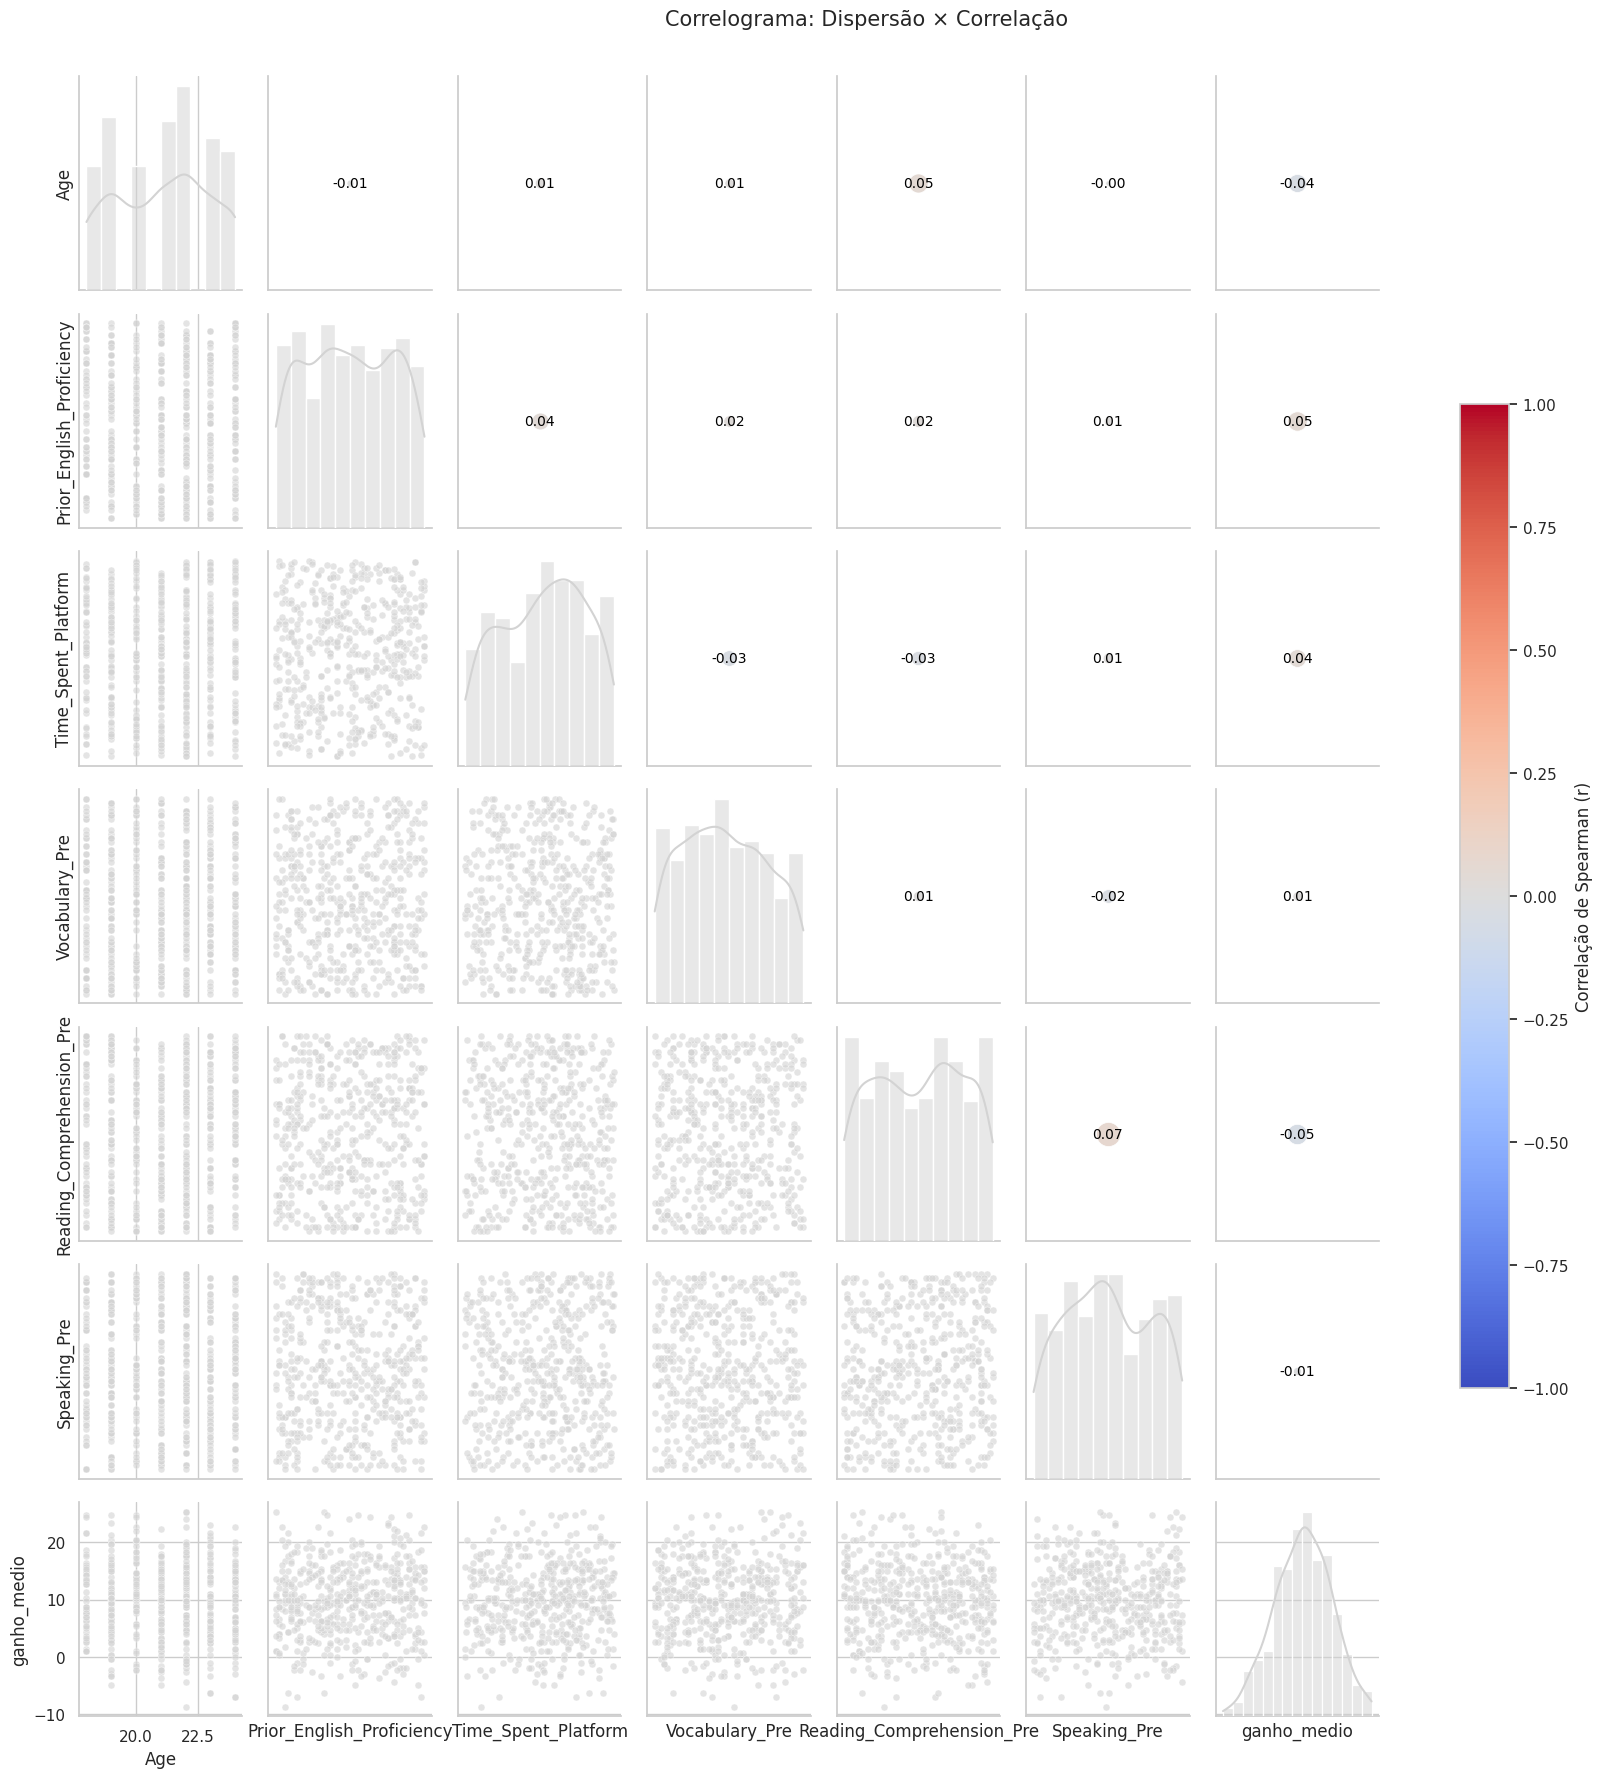

In [ ]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = stats.spearmanr(x, y)[0]   # Spearman, pra ficar coerente com o heatmap acima
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,          # tamanho proporcional à força da correlação
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

VARS_CORRELOGRAMA = VARS_PREDITORAS + ["ganho_medio"]

g = sns.PairGrid(df[VARS_CORRELOGRAMA], diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação de Spearman (r)")

g.fig.suptitle("Correlograma: Dispersão × Correlação", y=1.02, fontsize=15)
plt.show()

**Pra discutir:** algum painel inferior mostra um padrão (linha, curva, agrupamentos)? Algum círculo é grande o suficiente pra chamar atenção?

*Resposta*: Não, todos os gráficos de dispersão são "quadrados" preenchidos por igual, e os histogramas da diagonal são achatados (uniformes), exceto o do `ganho_medio`, que tem formato mais parecido com um sino por ser a média de três colunas. Todos os círculos são pequenos, confirmando pela terceira vez (Pearson/Spearman, heatmap e correlograma) que as variáveis não se relacionam entre si.

## Síntese

### Principais conclusões

1. **A base é limpa, mas parece sintética.** Não há valores ausentes (nem disfarçados), nem outliers pela regra do IQR, nem linhas duplicadas. Por outro lado, todas as variáveis numéricas têm distribuição uniforme (assimetria ≈ 0, curtose ≈ -1,2, QQ-Plot em "S" e Shapiro-Wilk rejeitando), o que é muito difícil de acontecer com alunos reais.
2. **As colunas de ganho não batem com as notas.** O `Improvement` informado só é igual a Pós − Pré em cerca de 1% a 2% das linhas. Mantive o ganho informado como alvo (é o target declarado), mas essa é a maior limitação da análise.
3. **Nenhuma variável explica o ganho.** Idade, tempo de plataforma, notas pré, estilo de aprendizagem e motivação não mostraram diferença entre alunos de alto e baixo ganho. A única exceção, proficiência prévia (p ≈ 0,047), está no limite e provavelmente é acaso.
4. **As variáveis não se relacionam entre si.** Entre as variáveis originais, todas as correlações ficaram abaixo de 0,10 em módulo (as únicas maiores são as do `ganho_medio` com as colunas das quais ele é a média), até entre pares que deveriam estar ligados (nota pré x nota pós da mesma habilidade).
5. **Não apareceu diferença entre grupos (fairness).** A proporção de alto ganho é parecida entre gêneros e faixas etárias. Mas, como os dados parecem gerados de forma independente, isso não permite concluir que uma plataforma real seria justa com todos. Pra um modelo preditivo, esta base provavelmente não serviria.

### Declaração de Uso de IA

- **Ferramenta utilizada:** Gemini e Claude.

- **Para o que foi aplicada:** Revisar o notebook depois que eu já tinha adaptado parte do código na aula. Me ajudar nas justificativas para ficarem mais compreensíveis e ver se o meu ponto de vista estava correto.

- **O que foi aceito, modificado ou rejeitado, e por quê:**
A adaptação inicial do notebook
  (escolha das variáveis, criação do alvo pela mediana, checagem de ausentes disfarçados e a
  checagem de ganho = Pós − Pré) foi feita por mim. Depois usei a IA para revisar o notebook e me auxiliar nos argumentos, gostei das sugestões e do auxílio delas e, por isso, mantive:
  - correção dos textos que ainda se referiam ao dataset Heart Disease e das afirmações que não batiam com os resultados;
  - justificativas dos passos da aula que não precisaram ser executados;
  - investigação dos `Student_ID` repetidos e aprofundamento da inconsistência do ganho;
  - respostas às perguntas de discussão.

  - rejeitei uma revisão do Gemini que apontava células duplicadas, um gráfico por classe faltando e seções ausentes, porque conferi no notebook e esses problemas não existiam (provavelmente ele não leu o arquivo inteiro).